# Mercado — ¿quién gana y dónde falla?

**Objetivo.** Responder dos preguntas con validación temporal:

- **A. ¿Quién gana?** Comparar un modelo que usa **solo las cuotas** con otro que usa **solo estadísticas de equipo y habilidades de jugadores (sin cuotas)**, ambos prediciendo la diferencia de goles, y estudiar qué pasa cuando **discrepan** y si combinarlos ayuda.
- **B. ¿Dónde falla el mercado?** Calibración de las probabilidades implícitas por tramo, resultado, liga y temporada, con intervalos de confianza y corrección por pruebas múltiples.

Entrada: `dataset_final.csv`, `dataset_skills.csv`, `backtest_odds.csv` y `feature_sets.json` (generados por `02_feature.ipynb`). Salida: `predicciones_oof.csv` (predicciones fuera de muestra, que reutilizarán el backtest y los modelos finales).

> **Esquema train/val/test (test holdout).** Las dos últimas temporadas, **2024/25 y 2025/26** (5,999 partidos, 16.6 % de los 36,119), se reservan como **test final**: no se usan para entrenar, validar, elegir hiperparámetros, variables ni umbrales, y solo se evalúan **una vez** en `08_modelo_final.ipynb` (Paso 8). Todo lo demás —**30,120 partidos, 2014/15–2023/24**— es *train/val*: los folds de validación son las seis temporadas **2018/19–2023/24** (cada una se valida con todo lo anterior). Los cuadernos 04–08 definen `TEST_SEASONS = [2425, 2526]` y `TEST_MASK`; ningún ajuste (`fit`) puede ver una fila de test porque los folds terminan en 2023/24.

## Paso 0 — Carga y esquema de validación

**Qué vamos a hacer.** Cargar las tres tablas (alineadas fila a fila) y definir dos conjuntos de temporadas **disjuntos**:

- **Ventana de ajuste (2016/17 y 2017/18):** solo se usó para elegir los hiperparámetros (en `04_modelo.ipynb`, Paso 6a).
- **Folds de evaluación (2018/19 – 2023/24):** ventana expansiva, igual que en `04_modelo.ipynb`. Nunca se usan para elegir hiperparámetros.

**Por qué.** Si los hiperparámetros se eligieran mirando los folds de evaluación, el resultado reportado sería optimista.

In [1]:
import json
import warnings
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest, norm
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.metrics import log_loss, accuracy_score

warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
DATA = '../data/'
df = pd.read_csv(DATA + 'dataset_final.csv')
sk = pd.read_csv(DATA + 'dataset_skills.csv')
odds = pd.read_csv(DATA + 'backtest_odds.csv')
fs = json.load(open(DATA + 'feature_sets.json'))
for t in (sk, odds):
    assert (t[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
SK = fs['SK_habilidades']
X = pd.concat([df.reset_index(drop=True), sk[SK]], axis=1)
y = df['FTR'].map({'H': 0, 'D': 1, 'A': 2}).to_numpy()
GD = sk['GD'].to_numpy(float)
seas = df['Season'].to_numpy()
liga = df['Div'].to_numpy()

MKT = ['MKT_logit', 'MKT_pD', 'MKT_margin']
MKT_MIN = ['MKT_logit', 'MKT_pD']
SQ = ['DIF_sq_top11', 'HomeTeam_sq_top11_mean']
FORMA = [f for f in fs['F1_sin_nan'] if f.startswith(('H_', 'A_'))]
F1 = fs['F1_sin_nan']
NM = SQ + FORMA + SK                    # bloque SIN cuotas: plantilla + forma + habilidades
temporadas = sorted(np.unique(seas))
TUNE = [1617, 1718]
TEST_SEASONS = [2425, 2526]; TEST_MASK = np.isin(seas, TEST_SEASONS)   # test holdout: no se toca hasta 08_modelo_final.ipynb
FOLDS = [s for s in temporadas if s >= 1819 and s not in TEST_SEASONS]
assert max(FOLDS) < min(TEST_SEASONS)
prev_de = {s: temporadas[temporadas.index(s) - 1] for s in temporadas[1:]}
print('filas:', len(X), '| bloque sin cuotas:', len(NM), 'features | mercado minimo:', MKT_MIN)
print('ventana de ajuste:', TUNE, '| folds de evaluacion:', [int(s) for s in FOLDS])
print('traslape entre ambas:', set(TUNE) & set(FOLDS))

def forest(ax, nombres, delta, lo, hi, titulo, xlabel='Δ log loss (negativo = mejor que la referencia)', fmt='{:+.4f}', positivo_bueno=False):
    """Delta con IC (95%): verde = mejora distinguible del ruido, rojo = empeora, gris = indistinguible (con positivo_bueno=True se invierte el sentido)."""
    ypos = np.arange(len(nombres))[::-1]
    for yi, d, l, h in zip(ypos, delta, lo, hi):
        ref = (l == h == 0) or np.isnan(l)
        bueno_, malo_ = (l > 0, h < 0) if positivo_bueno else (h < 0, l > 0)
        c = 'black' if ref else ('tab:green' if bueno_ else 'tab:red' if malo_ else 'gray')
        if not ref: ax.plot([l, h], [yi, yi], color=c, lw=2.2)
        ax.plot(d, yi, 'o' if not ref else 's', color=c, ms=5)
        ax.annotate(fmt.format(d), (d if ref else max(d, h), yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=7, color=c)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(ypos); ax.set_yticklabels(nombres, fontsize=8); ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel, fontsize=8)
    ax.margins(x=0.18)

filas: 36119 | bloque sin cuotas: 43 features | mercado minimo: ['MKT_logit', 'MKT_pD']
ventana de ajuste: [1617, 1718] | folds de evaluacion: [1819, 1920, 2021, 2122, 2223, 2324]
traslape entre ambas: set()


**Hallazgo.** 36,119 partidos. El bloque **sin cuotas** tiene 43 features (2 de plantilla, 8 de forma y 33 habilidades). La ventana de ajuste (2016/17–2017/18) y los 6 folds de evaluación (2018/19–2023/24) **no se solapan**. Las temporadas 2024/25 y 2025/26 son el test holdout y **no intervienen en este cuaderno**: ni en las predicciones, ni en los análisis de calibración del mercado (Pasos 4 y 5), ni en el backtest.

**Decisión.** Los hiperparámetros se eligen solo con la ventana de ajuste; los folds de evaluación quedan intactos.

## Paso 1 — Carga de los hiperparámetros (elegidos en `04_modelo.ipynb`)

**Qué vamos a hacer.** Cargar los hiperparámetros de LR, HGB (clasificación) y RF, HGB (regresión de la diferencia de goles) que se eligieron en `04_modelo.ipynb` (Paso 6a): rejilla corta, validación temporal en la ventana de ajuste (2016/17 y 2017/18) disjunta de los folds de evaluación, y desempate por simplicidad. Se reconstruyen aquí las fábricas de modelos.

**Por qué.** La selección se hace una sola vez, en el cuaderno que compara los modelos, y todos los demás cuadernos usan los mismos valores congelados; así el backtest y el análisis de este cuaderno no dependen de una elección distinta.

In [2]:
mk_lr = lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
mk_hgbc = lambda learning_rate, max_depth, min_samples_leaf, max_iter: HistGradientBoostingClassifier(
    learning_rate=learning_rate, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_iter=max_iter, l2_regularization=1.0, random_state=42)
mk_rf = lambda min_samples_leaf, max_features: RandomForestRegressor(
    n_estimators=100, min_samples_leaf=min_samples_leaf, max_features=max_features, max_samples=0.5, n_jobs=-1, random_state=42)
mk_hgbr = lambda learning_rate, max_depth, min_samples_leaf, max_iter: HistGradientBoostingRegressor(
    learning_rate=learning_rate, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_iter=max_iter, l2_regularization=1.0, random_state=42)
BEST = json.load(open(DATA + 'hiperparametros.json'))
for k, v in BEST.items():
    print(k, {a: (round(b, 4) if isinstance(b, float) else b) for a, b in v.items()})

LR_clas {'C': 0.05, 'll': 0.9429}
HGB_clas {'learning_rate': 0.03, 'max_depth': 2.0, 'min_samples_leaf': 50.0, 'max_iter': 100.0, 'll': 0.9481}
RF_reg {'min_samples_leaf': 20.0, 'max_features': 0.5, 'rmse': 1.649}
HGB_reg {'learning_rate': 0.1, 'max_depth': 2.0, 'min_samples_leaf': 50.0, 'max_iter': 100.0, 'rmse': 1.6508}


**Qué encontramos.** Se cargaron los valores congelados en `04_modelo.ipynb`: LR con `C = 0.05`; HGB de clasificación con `learning_rate = 0.03`, `max_depth = 2`, `min_samples_leaf = 50`, `max_iter = 100`; RF de regresión con `min_samples_leaf = 20`, `max_features = 0.5`; y HGB de regresión con `learning_rate = 0.1`, `max_depth = 2`, `min_samples_leaf = 50`, `max_iter = 100`.

**Qué significa para nuestro caso.** Los modelos de este cuaderno usan los mismos hiperparámetros que los de la comparación de modelos, elegidos sin mirar los folds de evaluación.

**Decisión.** Usar estos valores para las predicciones fuera de muestra del Paso 2.

## Paso 2 — Predicciones fuera de muestra con los hiperparámetros elegidos

**Qué vamos a hacer.** Para cada fold de evaluación `s`, entrenar con todas las temporadas anteriores y predecir `s`. Se generan:

| Etiqueta | Qué es |
|---|---|
| `y_M` | Diferencia de goles predicha **solo con cuotas** (regresión lineal sobre `MKT_logit` y `MKT_pD`) |
| `y_NM` | Diferencia de goles predicha **sin cuotas** (promedio de LIN, RF y HGB sobre plantilla, forma y habilidades): el *ensemble* del paper |
| `y_avg` | Promedio simple de `y_M` y `y_NM` |
| `P_mkt` | Probabilidades del mercado tal cual (sin modelo) |
| `P_M`, `P_NM`, `P_avg` | Probabilidades 1X2 derivadas de cada `ŷ` |
| `P_stack` | Regresión logística sobre `[MKT_logit, y_NM]` (combinación) |
| `P_lr`, `P_hgb` | Clasificación directa (LR sobre cuotas; HGB sobre F1) |

**Cómo se convierte `ŷ` en probabilidades.** Con una regresión logística multinomial entrenada en la **temporada inmediatamente anterior** a `s` (usando predicciones de un modelo que solo vio temporadas previas a esa), para no usar predicciones *in-sample*.

**Por qué guardarlas.** El backtest y los modelos finales deben usar exactamente estas predicciones.

In [3]:
def mk_models():
    return {'LIN': lambda: make_pipeline(StandardScaler(), LinearRegression()),
            'RF': lambda: mk_rf(int(BEST['RF_reg']['min_samples_leaf']), float(BEST['RF_reg']['max_features'])),
            'HGB': lambda: mk_hgbr(float(BEST['HGB_reg']['learning_rate']), int(BEST['HGB_reg']['max_depth']),
                                   int(BEST['HGB_reg']['min_samples_leaf']), int(BEST['HGB_reg']['max_iter']))}
REGM = mk_models()
mkl = X['MKT_logit'].to_numpy()

def ajusta(fab, cols, tr_c, ca, tr, va):
    mc = fab().fit(X.loc[tr_c, cols], GD[tr_c]); m = fab().fit(X.loc[tr, cols], GD[tr])
    return mc.predict(X.loc[ca, cols]), m.predict(X.loc[va, cols]), m

def calib(zc, yc, zv):
    return LogisticRegression(C=10.0, max_iter=3000).fit(zc, yc).predict_proba(zv)

oof = []
resid = []
for s in FOLDS:
    va, tr = seas == s, seas < s
    p = prev_de[s]
    tr_c, ca = seas < p, seas == p
    # --- regresion de la diferencia de goles
    yM_c, yM_v, mM = ajusta(REGM['LIN'], MKT_MIN, tr_c, ca, tr, va)
    cs, vs = [], []
    for nombre in ('LIN', 'RF', 'HGB'):
        c_, v_, _ = ajusta(REGM[nombre], NM, tr_c, ca, tr, va)
        cs.append(c_); vs.append(v_)
    yN_c, yN_v = np.mean(cs, axis=0), np.mean(vs, axis=0)
    yA_c, yA_v = (yM_c + yN_c) / 2, (yM_v + yN_v) / 2
    # --- probabilidades derivadas
    P_M = calib(yM_c[:, None], y[ca], yM_v[:, None])
    P_NM = calib(yN_c[:, None], y[ca], yN_v[:, None])
    P_avg = calib(yA_c[:, None], y[ca], yA_v[:, None])
    P_stack = calib(np.c_[mkl[ca], yN_c], y[ca], np.c_[mkl[va], yN_v])
    P_mk_cal = calib(mkl[ca][:, None], y[ca], mkl[va][:, None])
    # --- clasificacion directa
    P_lr = mk_lr(float(BEST['LR_clas']['C'])).fit(X.loc[tr, MKT], y[tr]).predict_proba(X.loc[va, MKT])
    P_hgb = mk_hgbc(float(BEST['HGB_clas']['learning_rate']), int(BEST['HGB_clas']['max_depth']),
                    int(BEST['HGB_clas']['min_samples_leaf']), int(BEST['HGB_clas']['max_iter'])).fit(X.loc[tr, F1], y[tr]).predict_proba(X.loc[va, F1])
    # --- modelo de residuo: lo que las cuotas NO explican de la diferencia de goles
    r_tr = GD[tr] - mM.predict(X.loc[tr, MKT_MIN])
    r_va = GD[va] - yM_v
    mr = REGM['HGB']().fit(X.loc[tr, NM], r_tr)
    r_hat = mr.predict(X.loc[va, NM])
    r2 = 1 - np.sum((r_va - r_hat) ** 2) / np.sum((r_va - r_tr.mean()) ** 2)
    resid.append(dict(fold=int(s), r2_residuo=r2, corr=float(np.corrcoef(r_hat, r_va)[0, 1])))
    d = pd.DataFrame({'fold': int(s), 'idx': np.where(va)[0], 'y': y[va], 'GD': GD[va], 'Div': liga[va],
                      'y_M': yM_v, 'y_NM': yN_v, 'y_avg': yA_v})
    for nombre, P in (('mkt', odds.loc[va, ['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy()), ('mkcal', P_mk_cal), ('M', P_M), ('NM', P_NM),
                      ('avg', P_avg), ('stack', P_stack), ('lr', P_lr), ('hgb', P_hgb)):
        for j, l in enumerate('HDA'):
            d[f'P_{nombre}_{l}'] = P[:, j]
    oof.append(d)
oof = pd.concat(oof, ignore_index=True)
oof = pd.concat([oof, df.loc[oof['idx'], ['Date', 'HomeTeam', 'AwayTeam']].reset_index(drop=True)], axis=1)
oof.to_csv(DATA + 'predicciones_oof.csv', index=False)
resid = pd.DataFrame(resid)
print('predicciones fuera de muestra:', oof.shape, '| folds:', sorted(oof.fold.unique()))
print('RMSE de GD  -> solo cuotas:', round(float(np.sqrt(((oof.GD - oof.y_M) ** 2).mean())), 4),
      '| sin cuotas:', round(float(np.sqrt(((oof.GD - oof.y_NM) ** 2).mean())), 4),
      '| promedio:', round(float(np.sqrt(((oof.GD - oof.y_avg) ** 2).mean())), 4))
print('correlacion y_M vs y_NM:', round(float(np.corrcoef(oof.y_M, oof.y_NM)[0, 1]), 3))

predicciones fuera de muestra: (18184, 35) | folds: [np.int64(1819), np.int64(1920), np.int64(2021), np.int64(2122), np.int64(2223), np.int64(2324)]
RMSE de GD  -> solo cuotas: 1.6247 | sin cuotas: 1.6704 | promedio: 1.6374
correlacion y_M vs y_NM: 0.911


**Hallazgo.** Se generaron **18,184 predicciones fuera de muestra** (6 folds) guardadas en `predicciones_oof.csv`.

| Predicción de la diferencia de goles | RMSE |
|---|---|
| Solo cuotas (`y_M`) | **1.6247** |
| Sin cuotas, ensemble (`y_NM`) | 1.6704 |
| Promedio de ambas (`y_avg`) | 1.6374 |

La correlación entre `y_M` y `y_NM` es **0.911**: el modelo sin cuotas reproduce casi la misma ordenación de equipos que el mercado.

**Decisión.** Usar estas predicciones para el análisis A, y reutilizarlas en el backtest y en los modelos finales.

## Paso 3 — A. ¿Quién gana? Cuotas vs. sin cuotas

**Qué vamos a hacer.** Comparar los modelos con tres métricas, y luego estudiar los partidos en que discrepan:

1. **Log loss y RPS** (*Ranked Probability Score*, que tiene en cuenta el orden H > D > A) sobre las probabilidades 1X2.
2. **Acierto del ganador** en partidos que no terminan en empate: se predice `H` si `ŷ > 0` y `A` si `ŷ < 0`. Es la forma natural de "decir quién gana a partir de la diferencia de goles".
3. **Desacuerdo:** en qué fracción de partidos los dos modelos predicen distinto ganador y quién acierta cuando discrepan. Se contrasta con la **prueba exacta de McNemar** (binomial sobre los pares discordantes).
4. **Modelo de residuo:** predecir lo que las cuotas **no** explican, `GD − ŷ_M`, con las features sin cuotas. Un `R²` fuera de muestra ≈ 0 significa que no hay información adicional.

**Por qué.** La pregunta central es si el modelo sin cuotas sabe algo que el mercado no sabe; el desacuerdo y el residuo son las dos formas más directas de verlo.


Partidos sin empate: 13665 (75.1%) | local gana: 0.583
acierto del ganador  -> siempre local: 0.5825 | cuotas: 0.7159 | sin cuotas: 0.6973 | promedio: 0.7105

Desacuerdo: 12.5% de los partidos sin empate (1704)
  cuando discrepan -> acierta solo cuotas: 979 | acierta solo sin cuotas: 725 | acierto de cuotas: 0.575
  McNemar exacto: p = 0.0
media R2 del residuo: -0.001 | folds con R2 > 0: 1 / 6


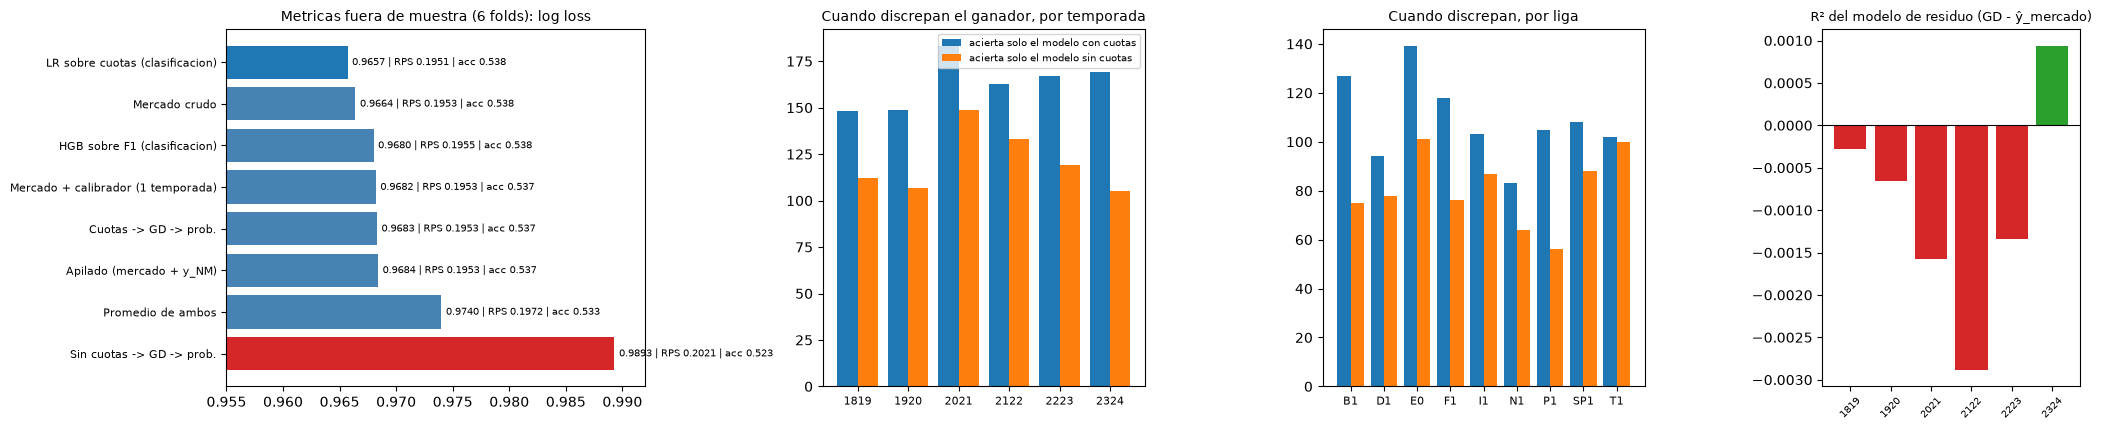

In [4]:
def rps(P, yy):
    O = np.eye(3)[yy]
    return float(np.mean(0.5 * (((np.cumsum(P, axis=1) - np.cumsum(O, axis=1))[:, :2]) ** 2).sum(axis=1)))

cols_P = lambda n: oof[[f'P_{n}_H', f'P_{n}_D', f'P_{n}_A']].to_numpy()
yy = oof['y'].to_numpy()
nombres = {'mkt': 'Mercado crudo', 'mkcal': 'Mercado + calibrador (1 temporada)', 'lr': 'LR sobre cuotas (clasificacion)', 'M': 'Cuotas -> GD -> prob.',
           'NM': 'Sin cuotas -> GD -> prob.', 'avg': 'Promedio de ambos', 'stack': 'Apilado (mercado + y_NM)', 'hgb': 'HGB sobre F1 (clasificacion)'}
filas = []
for k, nom in nombres.items():
    P = cols_P(k)
    filas.append(dict(modelo=nom, log_loss=log_loss(yy, P), rps=rps(P, yy), acc_1x2=accuracy_score(yy, P.argmax(1))))
tabla_a = pd.DataFrame(filas).round(4)

# acierto del ganador (partidos sin empate)
nd = yy != 1
real = (yy[nd] == 0)                                    # True si gana el local
pred_M = oof.y_M.to_numpy()[nd] > 0
pred_N = oof.y_NM.to_numpy()[nd] > 0
pred_A = oof.y_avg.to_numpy()[nd] > 0
print(f'\nPartidos sin empate: {int(nd.sum())} ({nd.mean():.1%}) | local gana: {real.mean():.3f}')
print('acierto del ganador  -> siempre local:', round(real.mean(), 4), '| cuotas:', round((pred_M == real).mean(), 4),
      '| sin cuotas:', round((pred_N == real).mean(), 4), '| promedio:', round((pred_A == real).mean(), 4))

# desacuerdo
dis = pred_M != pred_N
b = int(((pred_M == real) & (pred_N != real)).sum())      # acierta solo cuotas
c = int(((pred_N == real) & (pred_M != real)).sum())      # acierta solo sin cuotas
print(f'\nDesacuerdo: {dis.mean():.1%} de los partidos sin empate ({int(dis.sum())})')
print(f'  cuando discrepan -> acierta solo cuotas: {b} | acierta solo sin cuotas: {c} | acierto de cuotas: {b / (b + c):.3f}')
print('  McNemar exacto: p =', round(binomtest(b, b + c, 0.5).pvalue, 4))
por_fold = pd.DataFrame({'fold': oof.fold[nd].to_numpy(), 'dis': dis, 'cuotas_ok': (pred_M == real) & dis, 'sin_ok': (pred_N == real) & dis}).groupby('fold').agg(
    discrepan=('dis', 'mean'), solo_cuotas=('cuotas_ok', 'sum'), solo_sin_cuotas=('sin_ok', 'sum')).round(3)
por_liga = pd.DataFrame({'Div': oof.Div[nd].to_numpy(), 'dis': dis, 'cuotas_ok': (pred_M == real) & dis, 'sin_ok': (pred_N == real) & dis}).groupby('Div').agg(
    n=('dis', 'size'), discrepan=('dis', 'mean'), solo_cuotas=('cuotas_ok', 'sum'), solo_sin_cuotas=('sin_ok', 'sum')).round(3)

print('media R2 del residuo:', round(float(resid.r2_residuo.mean()), 4), '| folds con R2 > 0:', int((resid.r2_residuo > 0).sum()), '/', len(resid))
fig, axs = plt.subplots(1, 4, figsize=(21, 4.4), gridspec_kw={'width_ratios': [1.3, 1, 1, 0.8]})
ta = tabla_a.sort_values('log_loss', ascending=False)
axs[0].barh(range(len(ta)), ta.log_loss, color=['tab:red' if v > 0.985 else 'tab:blue' if 'LR' in n_ else 'steelblue' for n_, v in zip(ta.modelo, ta.log_loss)]); axs[0].set_xlim(0.955, 0.992); axs[0].set_yticks(range(len(ta))); axs[0].set_yticklabels(ta.modelo, fontsize=8)
for yi, (v, r_, a_) in enumerate(zip(ta.log_loss, ta.rps, ta.acc_1x2)): axs[0].text(v + 0.0004, yi, f'{v:.4f} | RPS {r_:.4f} | acc {a_:.3f}', va='center', fontsize=7)
axs[0].set_title('Metricas fuera de muestra (6 folds): log loss', fontsize=10)
xs = np.arange(len(por_fold)); axs[1].bar(xs - 0.2, por_fold.solo_cuotas, 0.4, color='tab:blue', label='acierta solo el modelo con cuotas'); axs[1].bar(xs + 0.2, por_fold.solo_sin_cuotas, 0.4, color='tab:orange', label='acierta solo el modelo sin cuotas')
axs[1].set_xticks(xs); axs[1].set_xticklabels(por_fold.index, fontsize=8); axs[1].legend(fontsize=7); axs[1].set_title('Cuando discrepan el ganador, por temporada', fontsize=10)
xl = np.arange(len(por_liga)); axs[2].bar(xl - 0.2, por_liga.solo_cuotas, 0.4, color='tab:blue'); axs[2].bar(xl + 0.2, por_liga.solo_sin_cuotas, 0.4, color='tab:orange'); axs[2].set_xticks(xl); axs[2].set_xticklabels(por_liga.index, fontsize=8); axs[2].set_title('Cuando discrepan, por liga', fontsize=10)
axs[3].bar(range(len(resid)), resid.r2_residuo, color=['tab:green' if v > 0 else 'tab:red' for v in resid.r2_residuo]); axs[3].axhline(0, color='k', lw=0.8); axs[3].set_xticks(range(len(resid))); axs[3].set_xticklabels(resid.fold, fontsize=7, rotation=45); axs[3].set_title('R² del modelo de residuo (GD - ŷ_mercado)', fontsize=9)
plt.tight_layout(); plt.show()

**Hallazgo.**

| Modelo | Log loss | RPS | Acierto 1X2 |
|---|---|---|---|
| Mercado crudo | 0.9664 | 0.1953 | 0.538 |
| **LR sobre cuotas** | **0.9657** | **0.1951** | 0.538 |
| Cuotas → GD → prob. | 0.9683 | 0.1953 | 0.537 |
| HGB sobre F1 | 0.9680 | 0.1955 | 0.538 |
| Apilado (mercado + `y_NM`) | 0.9684 | 0.1953 | 0.537 |
| Promedio de ambos | 0.9740 | 0.1972 | 0.534 |
| **Sin cuotas → GD → prob.** | 0.9893 | 0.2021 | 0.523 |

**Acierto del ganador** (partidos sin empate, 75.1% del total, n = 13,665):

| Regla | Acierto |
|---|---|
| Siempre local | 0.583 |
| **Cuotas** (`ŷ_M > 0`) | **0.716** |
| Sin cuotas (`ŷ_NM > 0`) | 0.697 |
| Promedio | 0.711 |

**Desacuerdo.** Los dos modelos eligen distinto ganador en el **12.5%** de los partidos sin empate (1,704). Cuando discrepan acierta el modelo con cuotas en 979 casos y el modelo sin cuotas en 725: **57.5% vs 42.5%** (McNemar exacto, *p* < 0.0001). El patrón se repite en los 6 folds y en las 9 ligas (en Turquía casi empatan: 102 vs 100).

**Modelo de residuo.** Con las features sin cuotas, el `R²` fuera de muestra de `GD − ŷ_M` es **−0.001** en promedio y positivo solo en 1 de 6 folds (correlación ≈ 0): lo que las cuotas no explican **no** es predecible con estas features.

**Interpretación.**
- El modelo sin cuotas, con solo fundamentos, logra el **97%** del acierto de ganador del mercado (69.7% vs 71.6%): los fundamentos explican casi todo, pero el mercado sabe algo más.
- Ese "algo más" **no** está en las features disponibles: el residuo es ruido y combinar (promedio o apilado) no mejora; el promedio incluso empeora porque mezcla con un modelo peor.

**Decisión.** Conservar las cuotas como referencia. El modelo sin cuotas es un *benchmark* independiente útil para el informe, no una alternativa.

## Paso 4 — B. Calibración del mercado

**Qué vamos a hacer.** Medir si las probabilidades implícitas del mercado coinciden con las frecuencias reales, sobre **todos los partidos** (no hay nada que ajustar, así que no hace falta separar entrenamiento y validación):

1. **Curva de fiabilidad** por resultado (H, D, A): frecuencia observada vs probabilidad implícita en tramos, con intervalo de Wilson al 95%.
2. **ECE** (error de calibración esperado) con intervalo por *bootstrap*.
3. **Pendiente de calibración:** regresión logística del resultado sobre `logit(p)`. Pendiente > 1 = el mercado es *poco confiado* (subestima a los favoritos, sesgo favorito–longshot); < 1 = *demasiado confiado*.
4. **Sensibilidad al método de normalización del margen:** proporcional (`p = (1/o)/Σ(1/o)`, el que usamos) vs. método de la **potencia** (`p = (1/o)^k` con `k` tal que `Σp = 1`), que reparte el margen de forma distinta entre favoritos y longshots. Se calcula sobre las cuotas crudas de B365.

**Por qué.** El sesgo favorito–longshot depende en parte de cómo se elimina el margen; si la conclusión cambia con el método, no es robusta.

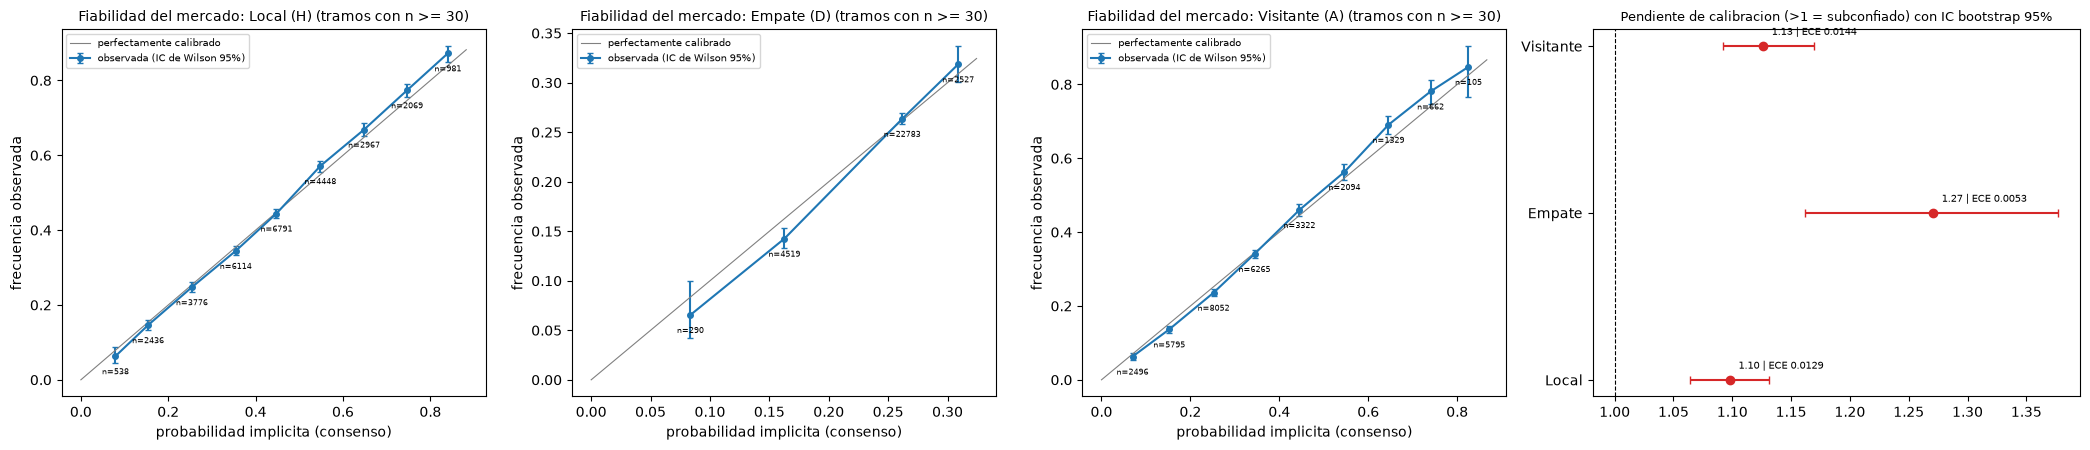

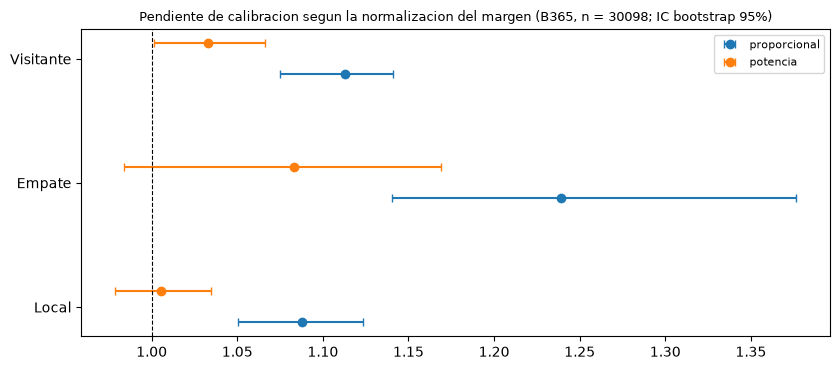

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h

TV = ~TEST_MASK   # analisis descriptivo del mercado: solo train/val (el test holdout no se mira)
odds_tv = odds[TV].reset_index(drop=True); y_tv, seas_tv, liga_tv = y[TV], seas[TV], liga[TV]
Pm = odds_tv[['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy()
EDGES = [0, .1, .2, .3, .4, .5, .6, .7, .8, 1.0]
rng = np.random.default_rng(7)
G = {}
for j, l in enumerate('HDA'):
    p = Pm[:, j]; o = (y_tv == j)
    b_ = pd.cut(p, EDGES, include_lowest=True)
    g = pd.DataFrame({'b': b_, 'o': o, 'p': p}).groupby('b', observed=True).agg(n=('o', 'size'), obs=('o', 'mean'), imp=('p', 'mean'), k=('o', 'sum'))
    g['dif'] = g.obs - g.imp
    g['ic_inf'], g['ic_sup'] = zip(*[wilson(k, n) for k, n in zip(g.k, g.n)])
    g['fuera_ic'] = (g.imp < g.ic_inf) | (g.imp > g.ic_sup)
    G[l] = g

def ece(p, o, edges=EDGES):
    b_ = np.digitize(p, edges[1:-1])
    tot = 0.0
    for k in np.unique(b_):
        m = b_ == k
        tot += m.mean() * abs(o[m].mean() - p[m].mean())
    return tot

def pendiente(p, o):
    z = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    m = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), o)
    return float(m.coef_[0, 0]), float(m.intercept_[0])

res_c = []
for j, l in enumerate('HDA'):
    p = Pm[:, j]; o = (y_tv == j)
    e = ece(p, o)
    sl, ic = pendiente(p, o)
    bs_e, bs_s = [], []
    for _ in range(300):
        ix = rng.integers(0, len(p), len(p))
        bs_e.append(ece(p[ix], o[ix])); bs_s.append(pendiente(p[ix], o[ix])[0])
    res_c.append(dict(resultado=l, ECE=e, ECE_lo=np.percentile(bs_e, 2.5), ECE_hi=np.percentile(bs_e, 97.5), pendiente=sl, pend_lo=np.percentile(bs_s, 2.5), pend_hi=np.percentile(bs_s, 97.5), intercepto=ic))
rc_ = pd.DataFrame(res_c)
fig, axs = plt.subplots(1, 4, figsize=(21, 4.6), gridspec_kw={'width_ratios': [1, 1, 1, 1.15]})
for ax, l, nom in zip(axs[:3], 'HDA', ['Local (H)', 'Empate (D)', 'Visitante (A)']):
    g = G[l][G[l].n >= 30]; ax.errorbar(g.imp, g.obs, yerr=[g.obs - g.ic_inf, g.ic_sup - g.obs], fmt='o-', ms=4, color='tab:blue', capsize=2, label='observada (IC de Wilson 95%)')
    ax.plot([0, g.imp.max() * 1.05], [0, g.imp.max() * 1.05], color='gray', lw=0.8, label='perfectamente calibrado')
    for x_, y_, n_ in zip(g.imp, g.obs, g.n): ax.annotate(f'n={n_}', (x_, y_), xytext=(0, -13), textcoords='offset points', ha='center', fontsize=6)
    ax.set_title(f'Fiabilidad del mercado: {nom} (tramos con n >= 30)', fontsize=10); ax.set_xlabel('probabilidad implicita (consenso)'); ax.set_ylabel('frecuencia observada'); ax.legend(fontsize=7, loc='upper left')
axs[3].errorbar(rc_.pendiente, range(3), xerr=[rc_.pendiente - rc_.pend_lo, rc_.pend_hi - rc_.pendiente], fmt='o', color='tab:red', capsize=3); axs[3].axvline(1, color='k', ls='--', lw=0.8)
axs[3].set_yticks(range(3)); axs[3].set_yticklabels(['Local', 'Empate', 'Visitante']); axs[3].set_title('Pendiente de calibracion (>1 = subconfiado) con IC bootstrap 95%', fontsize=9)
for yi, (sl_, e_) in enumerate(zip(rc_.pendiente, rc_.ECE)): axs[3].annotate(f'{sl_:.2f} | ECE {e_:.4f}', (sl_, yi), xytext=(6, 8), textcoords='offset points', fontsize=7)
plt.tight_layout(); plt.show()

# --- sensibilidad a la normalizacion (cuotas crudas de B365)
raw = odds[['B365H', 'B365D', 'B365A']].to_numpy(float)
ok = ~np.isnan(raw).any(axis=1) & TV
inv = 1 / raw[ok]
prop = inv / inv.sum(1, keepdims=True)
lo, hi = np.ones(ok.sum()), 4 * np.ones(ok.sum())
for _ in range(60):
    k = (lo + hi) / 2
    f_ = (inv ** k[:, None]).sum(1)
    lo, hi = np.where(f_ > 1, k, lo), np.where(f_ > 1, hi, k)
pot = inv ** ((lo + hi) / 2)[:, None]
yo = y[ok]
filas = []
for nombre, P in (('proporcional', prop), ('potencia', pot)):
    for j, l in enumerate('HDA'):
        p = P[:, j]; o = (yo == j)
        sl = pendiente(p, o)[0]
        bs = [pendiente(p[ix], o[ix])[0] for ix in (rng.integers(0, len(p), len(p)) for _ in range(150))]
        filas.append(dict(normalizacion=nombre, resultado=l, pendiente=sl, lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5), ece=ece(p, o)))
sn_ = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for k_, (nombre, col_) in enumerate((('proporcional', 'tab:blue'), ('potencia', 'tab:orange'))):
    sub_ = sn_[sn_.normalizacion == nombre]; ypos = np.arange(3) + (k_ - 0.5) * 0.25
    ax.errorbar(sub_.pendiente, ypos, xerr=[sub_.pendiente - sub_.lo, sub_.hi - sub_.pendiente], fmt='o', color=col_, capsize=3, label=nombre)
ax.axvline(1, color='k', ls='--', lw=0.8); ax.set_yticks(range(3)); ax.set_yticklabels(['Local', 'Empate', 'Visitante']); ax.legend(fontsize=8)
ax.set_title(f'Pendiente de calibracion segun la normalizacion del margen (B365, n = {int(ok.sum())}; IC bootstrap 95%)', fontsize=9); plt.tight_layout(); plt.show()

**Hallazgo.** (Solo train/val: 30,120 partidos de 2014/15–2023/24.)

*Curva de fiabilidad (probabilidad implícita del consenso, proporcional).* Tanto en local como en visitante, los favoritos ganan **más** de lo que implica el mercado y los longshots **menos**:

| Resultado | p ≤ 0.2 | 0.5–0.6 | 0.6–0.7 | 0.7–0.8 | > 0.8 |
|---|---|---|---|---|---|
| Local | −0.9 pp | +2.3 pp | +2.1 pp | +2.7 pp | **+3.2 pp** |
| Visitante | −1.3 pp | +1.7 pp | **+4.5 pp** | +4.1 pp | +2.2 pp (n = 105) |

*Pendiente de calibración (proporcional):* H = 1.10 [1.06, 1.13], D = 1.27 [1.16, 1.38], A = 1.13 [1.09, 1.17]; **ninguno incluye 1**. ECE: 0.0129 (H), 0.0053 (D), 0.0144 (A).

*Sensibilidad a la normalización del margen (B365):*

| Resultado | Pendiente proporcional | Pendiente potencia | ECE prop. → pot. |
|---|---|---|---|
| H | 1.09 [1.05, 1.12] | **1.01 [0.98, 1.03]** | 0.0120 → 0.0095 |
| D | 1.24 [1.14, 1.38] | 1.08 [0.98, 1.17] | 0.0050 → 0.0060 |
| A | 1.11 [1.08, 1.14] | 1.03 [1.00, 1.07] | 0.0132 → 0.0065 |

**Interpretación.** El mercado parece "poco confiado" (sesgo favorito–longshot) con la normalización proporcional. Con la normalización por potencia, que reparte más margen a los longshots, la pendiente cae a ≈ 1.01–1.08 y los intervalos casi incluyen 1: **buena parte del sesgo es consecuencia del método con que se elimina el margen**, no necesariamente un error del mercado.

**Decisión.** No afirmar un sesgo favorito–longshot sin el matiz de la normalización; reportar ambas versiones. Para los modelos no cambia nada: la regresión logística aprende la pendiente.

## Paso 5 — B. Temporadas y ligas (con corrección por pruebas múltiples)

**Qué vamos a hacer.** Buscar subconjuntos donde el mercado se desvíe de la frecuencia real:

- **Por temporada**, para el resultado local (incluye 2020/21, con estadios vacíos por la pandemia: un experimento natural sobre la ventaja de localía).
- **Por liga**, para local, empate y visitante.
- **Por tramo de favorito**: ROI de apostar una unidad a cada local en cada tramo de probabilidad, con las cuotas observadas de B365. Si el mercado fuera perfectamente eficiente, el ROI esperado sería ≈ −margen en todos los tramos.

**Estadístico.** Para cada subconjunto, `z = (O − E) / sqrt(Σ p(1 − p))` (O: aciertos observados; E: suma de probabilidades implícitas) y *p*-valor bilateral.

**Corrección.** Se hacen muchas pruebas (12 temporadas + 9 ligas × 3 resultados + tramos), por lo que se aplica **Benjamini–Hochberg al 5%** (ISLP cap. 13). Sin corrección algo saldría "significativo" por azar.

pruebas realizadas: 51 | significativas sin corregir (p<0.05): 13 | tras BH al 5%: 8


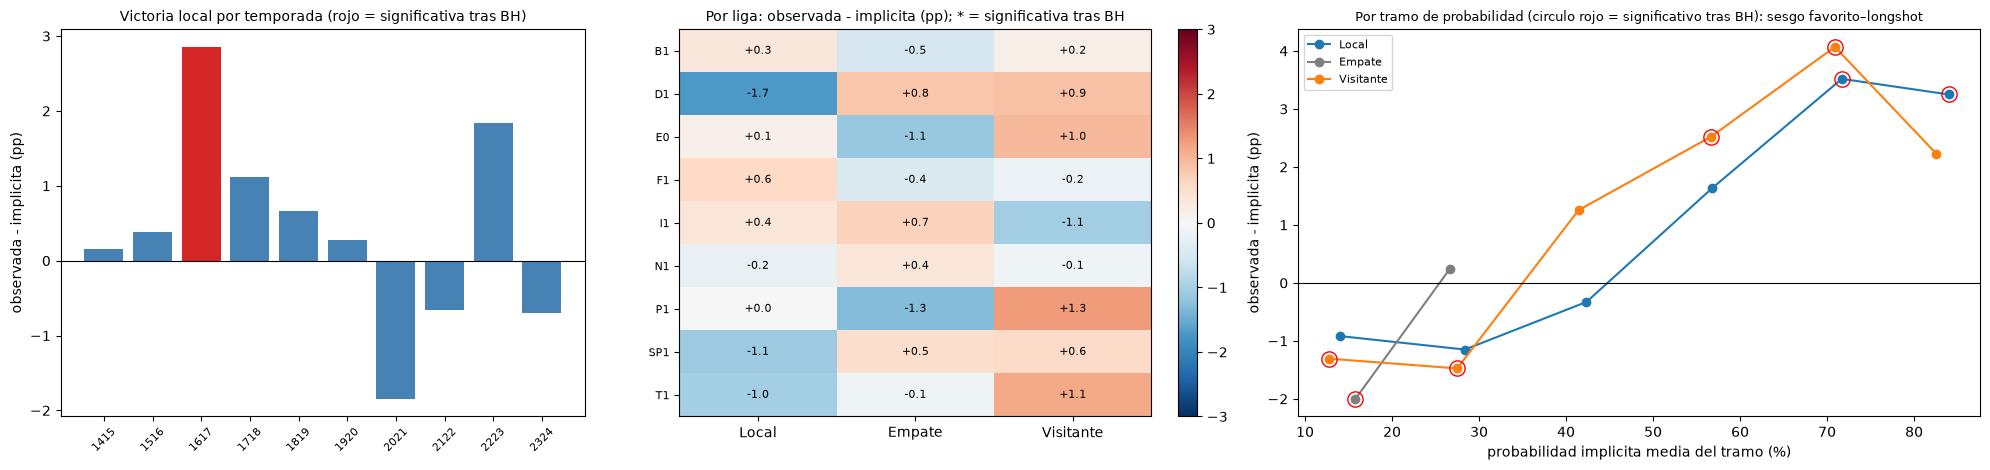

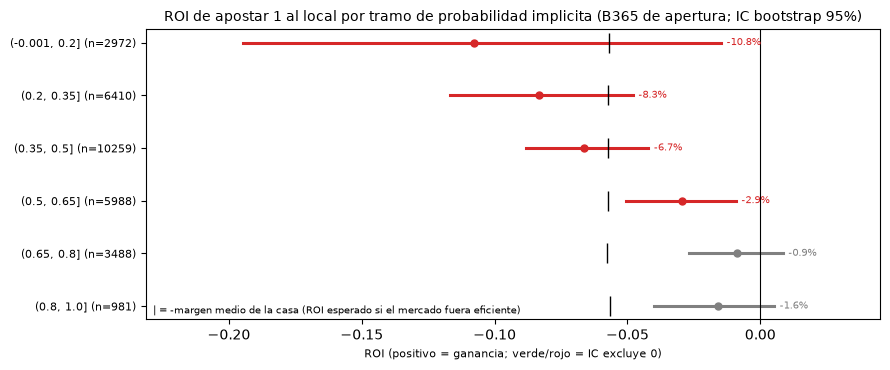

In [6]:
def z_test(o, p):
    O, E, V = o.sum(), p.sum(), (p * (1 - p)).sum()
    z = (O - E) / np.sqrt(V)
    return float(O / len(o)), float(E / len(o)), float(z), float(2 * (1 - norm.cdf(abs(z))))

pruebas = []
for s in [t_ for t_ in temporadas if t_ not in TEST_SEASONS]:
    m = seas_tv == s
    pruebas.append(dict(familia='temporada', grupo=int(s), resultado='H', n=int(m.sum()), **dict(zip(['obs', 'imp', 'z', 'p'], z_test(y_tv[m] == 0, Pm[m, 0])))))
for d_ in np.unique(liga_tv):
    m = liga_tv == d_
    for j, l in enumerate('HDA'):
        pruebas.append(dict(familia='liga', grupo=d_, resultado=l, n=int(m.sum()), **dict(zip(['obs', 'imp', 'z', 'p'], z_test(y_tv[m] == j, Pm[m, j])))))
for j, l in enumerate('HDA'):
    b_ = pd.cut(Pm[:, j], [0, .2, .35, .5, .65, .8, 1], include_lowest=True)
    for g in b_.categories:
        m = (b_ == g)
        if m.sum() > 50:
            pruebas.append(dict(familia='tramo', grupo=str(g), resultado=l, n=int(m.sum()), **dict(zip(['obs', 'imp', 'z', 'p'], z_test(y_tv[m] == j, Pm[m, j])))))
pr = pd.DataFrame(pruebas)
# Benjamini-Hochberg
o_ = pr.p.argsort().to_numpy(); m_ = len(pr)
bh = np.empty(m_); bh[o_] = pr.p.to_numpy()[o_] * m_ / (np.arange(m_) + 1)
bh_adj = np.minimum.accumulate(bh[o_][::-1])[::-1]
pr['p_bh'] = np.nan; pr.loc[o_, 'p_bh'] = np.minimum(bh_adj, 1)
pr['signif_5pct'] = pr.p_bh < 0.05
pr['dif_pp'] = (pr.obs - pr.imp) * 100
print('pruebas realizadas:', len(pr), '| significativas sin corregir (p<0.05):', int((pr.p < 0.05).sum()), '| tras BH al 5%:', int(pr.signif_5pct.sum()))
fig, axs = plt.subplots(1, 3, figsize=(20, 4.8), gridspec_kw={'width_ratios': [1, 1, 1.3]})
ts_ = pr[pr.familia == 'temporada']; axs[0].bar(range(len(ts_)), ts_.dif_pp, color=['tab:red' if s_ else 'steelblue' for s_ in ts_.signif_5pct]); axs[0].axhline(0, color='k', lw=0.8)
axs[0].set_xticks(range(len(ts_))); axs[0].set_xticklabels(ts_.grupo, rotation=45, fontsize=8); axs[0].set_ylabel('observada - implicita (pp)'); axs[0].set_title('Victoria local por temporada (rojo = significativa tras BH)', fontsize=10)
lg_ = pr[pr.familia == 'liga'].pivot(index='grupo', columns='resultado', values='dif_pp'); sg_ = pr[pr.familia == 'liga'].pivot(index='grupo', columns='resultado', values='signif_5pct')
im = axs[1].imshow(lg_.to_numpy(), cmap='RdBu_r', vmin=-3, vmax=3, aspect='auto'); axs[1].set_xticks(range(3)); axs[1].set_xticklabels(['Local', 'Empate', 'Visitante']); axs[1].set_yticks(range(len(lg_))); axs[1].set_yticklabels(lg_.index, fontsize=8)
for i_ in range(lg_.shape[0]):
    for j_ in range(lg_.shape[1]): axs[1].text(j_, i_, f"{lg_.iloc[i_, j_]:+.1f}{'*' if bool(sg_.iloc[i_, j_]) else ''}", ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=axs[1], fraction=0.05); axs[1].set_title('Por liga: observada - implicita (pp); * = significativa tras BH', fontsize=10)
tr_p = pr[pr.familia == 'tramo']
for l, col_, nom in (('H', 'tab:blue', 'Local'), ('D', 'tab:gray', 'Empate'), ('A', 'tab:orange', 'Visitante')):
    sub_ = tr_p[tr_p.resultado == l]; axs[2].plot(sub_.imp * 100, sub_.dif_pp, marker='o', color=col_, label=nom)
    for x_, y_, s_ in zip(sub_.imp * 100, sub_.dif_pp, sub_.signif_5pct):
        if s_: axs[2].plot(x_, y_, 'o', ms=11, mfc='none', mec='red')
axs[2].axhline(0, color='k', lw=0.8); axs[2].set_xlabel('probabilidad implicita media del tramo (%)'); axs[2].set_ylabel('observada - implicita (pp)'); axs[2].legend(fontsize=8); axs[2].set_title('Por tramo de probabilidad (circulo rojo = significativo tras BH): sesgo favorito–longshot', fontsize=9)
plt.tight_layout(); plt.show()
pr.to_csv(DATA + 'mercado_pruebas.csv', index=False)

# ROI de apostar 1 unidad al local por tramo de probabilidad implicita (cuotas observadas B365)
oh = odds_tv['B365H'].to_numpy(float); pnl = np.where(y_tv == 0, oh - 1, -1.0)
okk = ~np.isnan(oh)
tr_ = pd.cut(Pm[:, 0], [0, .2, .35, .5, .65, .8, 1], include_lowest=True)
filas = []
for g in tr_.categories:
    m = (tr_ == g) & okk
    ix = np.where(m)[0]
    bs = [pnl[rng.choice(ix, len(ix))].mean() for _ in range(300)]
    filas.append(dict(tramo=str(g), n=int(m.sum()), roi=pnl[m].mean(), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5), margen_medio=float((1 / odds_tv.loc[m, ['B365H', 'B365D', 'B365A']]).sum(axis=1).mean() - 1)))
roi_t = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(9, 3.8))
forest(ax, [f'{r.tramo} (n={r.n})' for r in roi_t.itertuples()], roi_t.roi.to_numpy(), roi_t.lo.to_numpy(), roi_t.hi.to_numpy(), 'ROI de apostar 1 al local por tramo de probabilidad implicita (B365 de apertura; IC bootstrap 95%)', xlabel='ROI (positivo = ganancia; verde/rojo = IC excluye 0)', fmt='{:+.1%}', positivo_bueno=True)
for yi, r in zip(np.arange(len(roi_t))[::-1], roi_t.itertuples()): ax.plot(-r.margen_medio, yi, marker='|', color='k', ms=14)
ax.text(0.01, 0.02, '| = -margen medio de la casa (ROI esperado si el mercado fuera eficiente)', transform=ax.transAxes, fontsize=7)
plt.tight_layout(); plt.show()

**Hallazgo.** Se realizaron **51 pruebas**: 13 significativas sin corregir (*p* < 0.05) y **8 tras Benjamini–Hochberg al 5%** (el 38% de los "hallazgos" sin corregir era ruido o se debilita).

*Temporadas (local):* solo **2016/17** es significativa tras la corrección (+2.9 pp, *p*_BH = 0.007). El experimento COVID: en **2020/21** el local gana 40.4% vs 42.2% implícito (−1.8 pp), con *p* = 0.024 sin corregir pero ***p*_BH = 0.12: no significativo**.

*Ligas:* **ninguna** de las 27 pruebas liga × resultado es significativa tras la corrección (la más extrema, Alemania visitante −1.7 pp, *p*_BH = 0.12). No hay evidencia de que alguna liga sea menos eficiente.

*Tramos (significativos tras BH):*

| Resultado | Tramo | Observada − implícita |
|---|---|---|
| Local | 0.65–0.8 / > 0.8 | +3.5 pp / +3.2 pp |
| Visitante | 0.5–0.65 / 0.65–0.8 | +2.5 pp / +4.1 pp |
| Visitante | ≤ 0.2 / 0.2–0.35 | −1.3 pp / −1.5 pp |
| Empate | ≤ 0.2 | −2.0 pp |

*ROI de apostar 1 al local por tramo (B365, apertura; margen medio 5.7%):*

| Tramo de prob. implícita | ROI | IC 95% |
|---|---|---|
| ≤ 0.2 | −10.8% | [−19.5%, −1.5%] |
| 0.2–0.35 | −8.3% | [−11.7%, −4.8%] |
| 0.35–0.5 | −6.7% | [−8.8%, −4.2%] |
| 0.5–0.65 | −2.9% | [−5.0%, −0.9%] |
| 0.65–0.8 | −0.9% | [−2.7%, +0.9%] |
| > 0.8 | −1.6% | [−4.0%, +0.5%] |

**Interpretación.** El patrón de los tramos es el mismo del Paso 4: los favoritos rinden unos 5 pp mejor de lo que implica el margen, y los longshots peor. Pero **ningún tramo tiene ROI significativamente positivo** (los mejores incluyen 0 y su estimación puntual es negativa).

**Decisión.** Hay una desviación estadísticamente detectable pero pequeña (1–4 pp), parcialmente atribuible a la normalización, y insuficiente para una estrategia rentable. El backtest (siguiente paso) debe confirmarlo con un umbral de valor y con los resultados fuera de muestra.

## Paso 6 — C. Información entre la apertura y el cierre

**Qué vamos a hacer.** El mercado publica una cuota de **apertura** y otra de **cierre**, y entre ambas incorpora información nueva (alineaciones, lesiones, dinero apostado). Si el modelo sin cuotas supiera algo que la apertura no sabe, el mercado debería **moverse hacia él**. Se evalúa en tres partes, todas con **Pinnacle** (apertura `PSH/PSD/PSA` y cierre `PSC*`) para no mezclar efectos de casa:

1. **¿Cuánta información hay entre apertura y cierre?** Log loss de ambas y prueba de *encompassing*: regresión logística del resultado sobre `logit(p_apertura)` y `logit(p_cierre)`. Si el cierre es más eficiente, el coeficiente de la apertura debe ser ≈ 0.
2. **¿Anticipa el modelo el movimiento?** Correlación y pendiente entre la discrepancia `logit(P_NM,H) − logit(p_apertura,H)` y el movimiento `logit(p_cierre,H) − logit(p_apertura,H)`, y el porcentaje de veces que el movimiento va en la dirección del modelo (prueba binomial).
3. **Valor de línea de cierre (CLV):** apostando al lado donde el modelo supera a la apertura por más de un umbral `τ`, promedio de `p_cierre − p_apertura` en ese lado. CLV > 0 significa que se consiguió un precio mejor que el de cierre, que es la medida estándar de ventaja sin depender del resultado (mucho menos ruidosa que el ROI).

**Por qué.** Es la prueba más fina de "información que el mercado todavía no tenía": no necesita acertar resultados, solo ver si el precio se mueve hacia el modelo.

In [7]:
ps = pd.read_csv(DATA + 'matches_sq.csv', usecols=['Season', 'Date', 'HomeTeam', 'AwayTeam', 'PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA'])
o2 = oof.copy()
o2['Season'] = df.loc[o2['idx'], 'Season'].to_numpy()
mm = o2.merge(ps, on=['Season', 'Date', 'HomeTeam', 'AwayTeam'], how='left', validate='one_to_one')
asimetria = mm[['PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA']].notna().all(axis=1)
mm = mm[asimetria].reset_index(drop=True)
print('partidos de evaluacion:', len(o2), '| con Pinnacle apertura y cierre:', len(mm), f'({len(mm) / len(o2):.1%})')
print('cobertura por fold:', (mm.groupby('fold').size() / o2.groupby('fold').size()).round(3).to_dict())

def prob(cols):
    inv = 1 / mm[cols].to_numpy(float)
    return inv / inv.sum(1, keepdims=True)
PO, PC = prob(['PSH', 'PSD', 'PSA']), prob(['PSCH', 'PSCD', 'PSCA'])
yy = mm['y'].to_numpy()
lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
ll_o = -np.log(PO[np.arange(len(yy)), yy]).mean(); ll_c = -np.log(PC[np.arange(len(yy)), yy]).mean()
print(f'\nlog loss Pinnacle apertura: {ll_o:.4f} | cierre: {ll_c:.4f} | diferencia: {ll_o - ll_c:+.4f}')
mov = lg(PC[:, 0]) - lg(PO[:, 0])
print('movimiento del local (logit): media', round(float(mov.mean()), 4), '| desvio', round(float(mov.std()), 4), '| |mov| medio', round(float(np.abs(mov).mean()), 4))

# --- encompassing: el resultado ~ logit(apertura) + logit(cierre)
print('\nEncompassing (regresion logistica del resultado; bootstrap de 200 remuestreos):')
rng = np.random.default_rng(11)
filas = []
for j, l in enumerate('HDA'):
    Z = np.c_[lg(PO[:, j]), lg(PC[:, j])]
    t_ = (yy == j)
    mdl = LogisticRegression(C=1e6, max_iter=2000).fit(Z, t_)
    bs = []
    for _ in range(200):
        ix = rng.integers(0, len(t_), len(t_))
        bs.append(LogisticRegression(C=1e6, max_iter=2000).fit(Z[ix], t_[ix]).coef_[0])
    bs = np.array(bs)
    filas.append(dict(resultado=l, coef_apertura=mdl.coef_[0, 0], ic_ap=f'[{np.percentile(bs[:, 0], 2.5):+.2f}, {np.percentile(bs[:, 0], 97.5):+.2f}]',
                      coef_cierre=mdl.coef_[0, 1], ic_ci=f'[{np.percentile(bs[:, 1], 2.5):+.2f}, {np.percentile(bs[:, 1], 97.5):+.2f}]'))
print(pd.DataFrame(filas).round(3).to_string(index=False))

partidos de evaluacion: 18184 | con Pinnacle apertura y cierre: 18150 (99.8%)
cobertura por fold: {1819: 0.995, 1920: 0.998, 2021: 0.998, 2122: 0.999, 2223: 0.999, 2324: 0.999}

log loss Pinnacle apertura: 0.9658 | cierre: 0.9620 | diferencia: +0.0039
movimiento del local (logit): media -0.0065 | desvio 0.1525 | |mov| medio 0.117

Encompassing (regresion logistica del resultado; bootstrap de 200 remuestreos):


resultado  coef_apertura          ic_ap  coef_cierre          ic_ci
        H         -0.082 [-0.30, +0.15]        1.159 [+0.94, +1.37]
        D          0.289 [-0.16, +0.63]        0.963 [+0.63, +1.40]
        A          0.018 [-0.21, +0.21]        1.081 [+0.89, +1.31]


**Hallazgo.** 18,150 partidos de evaluación (99.8%) tienen Pinnacle de apertura y cierre. La cobertura es ≈ 99.5–99.9% en todos los folds (la caída de Pinnacle en 2025/26 afecta solo al test holdout, que no se usa aquí).

| | Log loss |
|---|---|
| Pinnacle apertura | 0.9658 |
| Pinnacle cierre | **0.9620** |
| Diferencia | +0.0039 |

- **El cierre es más informativo que la apertura** en 0.0039 de log loss: una ganancia más de cinco veces mayor que la recalibración de LR sobre las cuotas (0.0007) y mayor que cualquier mejora que hemos medido con features. Entre la apertura y el cierre el mercado incorpora información nueva (movimiento medio absoluto del local: 0.117 en logit, ≈ 2.4 pp de probabilidad).
- **Encompassing:** el coeficiente de la apertura es ≈ 0 en los tres resultados (H −0.08 [−0.30, +0.15]; D +0.29 [−0.16, +0.63]; A +0.02 [−0.21, +0.21]) y el del cierre es ≈ 1 (H 1.16 [0.94, 1.37]; D 0.96 [0.63, 1.40]; A 1.08 [0.89, 1.31]). **El cierre contiene toda la información de la apertura y más**: una vez conocido el cierre, la apertura no aporta nada.

**Decisión.** El cierre es el *benchmark* de eficiencia contra el que medir al modelo. Las cuotas de cierre **no** pueden usarse como feature (no se conocen antes del partido), tal como se definió desde el inicio.

In [8]:
# --- 2) anticipa el modelo sin cuotas el movimiento? (lado local)
disc = lg(mm['P_NM_H'].to_numpy()) - lg(PO[:, 0])
r = float(np.corrcoef(disc, mov)[0, 1])
pend, inter = np.polyfit(disc, mov, 1)
bs_p, bs_r = [], []
for _ in range(500):
    ix = rng.integers(0, len(disc), len(disc))
    bs_p.append(np.polyfit(disc[ix], mov[ix], 1)[0]); bs_r.append(np.corrcoef(disc[ix], mov[ix])[0, 1])
print(f'correlacion discrepancia-movimiento: r = {r:+.4f} [{np.percentile(bs_r, 2.5):+.4f}, {np.percentile(bs_r, 97.5):+.4f}]')
print(f'pendiente: {pend:+.4f} [{np.percentile(bs_p, 2.5):+.4f}, {np.percentile(bs_p, 97.5):+.4f}]  (1 = el mercado se mueve todo el camino hacia el modelo)')
print('desvio de la discrepancia:', round(float(disc.std()), 3), '| desvio del movimiento:', round(float(mov.std()), 3))

# misma prueba con la discrepancia de goles (sin transformar)
gd_disc = mm['y_NM'].to_numpy() - mm['y_M'].to_numpy()
print('correlacion (y_NM - y_M) vs movimiento:', round(float(np.corrcoef(gd_disc, mov)[0, 1]), 4))

print('\nPor fold (r, pendiente):')
por = []
for s, g in mm.assign(disc=disc, mov=mov).groupby('fold'):
    por.append(dict(fold=int(s), n=len(g), r=np.corrcoef(g.disc, g.mov)[0, 1], pendiente=np.polyfit(g.disc, g.mov, 1)[0]))
print(pd.DataFrame(por).round(4).to_string(index=False))

# direccion del movimiento segun el tamano de la discrepancia
dfm = pd.DataFrame({'disc': disc, 'mov': mov})
dfm['decil'] = pd.qcut(dfm['disc'].abs(), 5, labels=False)
print('\nPorcentaje de partidos donde el mercado se mueve en la direccion del modelo, por quintil de |discrepancia|:')
for q, g in dfm.groupby('decil'):
    k = int((np.sign(g.disc) == np.sign(g.mov)).sum()); n = len(g)
    print(f'  quintil {int(q) + 1}: |disc| medio {g.disc.abs().mean():.3f} | {k / n:.3f} ({k}/{n}) | p binomial = {binomtest(k, n, 0.5).pvalue:.4f}')
k = int((np.sign(disc) == np.sign(mov)).sum())
print(f'  todos: {k / len(disc):.3f} | p binomial = {binomtest(k, len(disc), 0.5).pvalue:.4g}')

correlacion discrepancia-movimiento: r = -0.0105 [-0.0272, +0.0048]
pendiente: -0.0042 [-0.0109, +0.0019]  (1 = el mercado se mueve todo el camino hacia el modelo)
desvio de la discrepancia: 0.381 | desvio del movimiento: 0.152
correlacion (y_NM - y_M) vs movimiento: -0.0017

Por fold (r, pendiente):
 fold    n       r  pendiente
 1819 2969  0.0714     0.0275
 1920 2794 -0.0055    -0.0023
 2021 3158  0.0566     0.0251
 2122 3120 -0.0556    -0.0240
 2223 3055 -0.0048    -0.0019
 2324 3054 -0.0457    -0.0190

Porcentaje de partidos donde el mercado se mueve en la direccion del modelo, por quintil de |discrepancia|:
  quintil 1: |disc| medio 0.047 | 0.496 (1800/3630) | p binomial = 0.6303
  quintil 2: |disc| medio 0.143 | 0.493 (1788/3630) | p binomial = 0.3790
  quintil 3: |disc| medio 0.250 | 0.500 (1814/3630) | p binomial = 0.9868
  quintil 4: |disc| medio 0.384 | 0.484 (1756/3630) | p binomial = 0.0521
  quintil 5: |disc| medio 0.672 | 0.490 (1777/3630) | p binomial = 0.2132
  todos: 

**Hallazgo.** Si el modelo sin cuotas supiera algo que la apertura no sabe, el mercado debería moverse hacia él. **No lo hace:**

- Correlación entre la discrepancia (modelo − apertura) y el movimiento (cierre − apertura): **r = −0.0105** [−0.027, +0.005]; pendiente −0.0042 [−0.0109, +0.0019]. Con la discrepancia medida en goles, r = −0.0017.
- Por fold, r oscila entre −0.056 y +0.071 sin signo consistente (positivo en 2 de 6).
- El mercado se mueve en la dirección del modelo en el **49.2%** de los partidos (*p* = 0.038, por debajo de 50%: si acaso, algo en contra del modelo), y en ningún quintil de |discrepancia| se aparta de forma relevante del 50% (48.4–50.0%, todos *p* ≥ 0.05), incluso en el quintil con discrepancias más grandes (|disc| medio 0.67).

**Interpretación.** Las discrepancias del modelo con la apertura son ruido de estimación respecto a lo que el mercado hará después: ni una pequeña parte del movimiento se explica por ellas.

**Decisión.** No hay evidencia de que el modelo sin cuotas contenga información que el mercado incorpore más tarde.

In [9]:
# --- 3) CLV: apostar al lado donde el modelo supera a la apertura por mas de tau
PNM = mm[['P_NM_H', 'P_NM_D', 'P_NM_A']].to_numpy()
ventaja = PNM - PO                                  # ventaja del modelo por lado respecto a la apertura de Pinnacle
ventaja[:, 1] = -np.inf                             # solo se apuesta a local o visitante
lado = ventaja.argmax(1)
vmax = ventaja.max(1)
clv_lado = (PC - PO)[np.arange(len(lado)), lado]      # movimiento en el lado elegido (puntos de probabilidad)
def boot_ic(v, n=500):
    b = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(n)]
    return np.percentile(b, 2.5), np.percentile(b, 97.5)

filas = []
for tau in (0.0, 0.02, 0.04, 0.06, 0.08):
    m = vmax > tau
    if m.sum() < 30:
        continue
    ic = boot_ic(clv_lado[m])
    filas.append(dict(tau=tau, apuestas=int(m.sum()), ventaja_media_modelo=float(vmax[m].mean()), CLV_medio=float(clv_lado[m].mean()),
                      ic=f'[{ic[0]:+.4f}, {ic[1]:+.4f}]', pct_clv_pos=float((clv_lado[m] > 0).mean())))
print('Modelo sin cuotas (apuesta al lado con mayor ventaja sobre la apertura de Pinnacle):')
print(pd.DataFrame(filas).round(4).to_string(index=False))

# referencias
fav = PO.argmax(1)
print('\nReferencias (CLV medio en puntos de probabilidad):')
print('  siempre local         :', round(float((PC - PO)[:, 0].mean()), 4))
print('  siempre favorito      :', round(float((PC - PO)[np.arange(len(fav)), fav].mean()), 4))
contra = ventaja.copy(); contra[:, 1] = np.inf
lado_c = np.where(vmax > 0.0, 2 - lado, lado)             # lado contrario al elegido por el modelo (H<->A)
print('  lado CONTRARIO al del modelo (tau = 0):', round(float((PC - PO)[np.arange(len(lado_c)), lado_c][vmax > 0].mean()), 4))
print('  media de |movimiento| local:', round(float(np.abs(PC - PO)[:, 0].mean()), 4))
# por temporada para tau = 0.04
m = vmax > 0.04
t_ = pd.DataFrame({'fold': mm.fold[m], 'clv': clv_lado[m]}).groupby('fold').clv.agg(['size', 'mean']).round(4)
print('\nCLV medio por fold (tau = 0.04):'); print(t_.to_string())

Modelo sin cuotas (apuesta al lado con mayor ventaja sobre la apertura de Pinnacle):
 tau  apuestas  ventaja_media_modelo  CLV_medio                 ic  pct_clv_pos
0.00     17261                0.0629    -0.0013 [-0.0017, -0.0009]       0.4731
0.02     14122                0.0744    -0.0011 [-0.0016, -0.0007]       0.4771
0.04     10513                0.0897    -0.0011 [-0.0017, -0.0006]       0.4741
0.06      7455                0.1062    -0.0014 [-0.0021, -0.0006]       0.4664
0.08      5044                0.1237    -0.0017 [-0.0027, -0.0009]       0.4617

Referencias (CLV medio en puntos de probabilidad):
  siempre local         : -0.001
  siempre favorito      : -0.0003
  lado CONTRARIO al del modelo (tau = 0): -0.0006
  media de |movimiento| local: 0.0243

CLV medio por fold (tau = 0.04):
      size    mean
fold              
1819  1711  0.0018
1920  1547 -0.0011
2021  1970  0.0001
2122  1833 -0.0048
2223  1641 -0.0015
2324  1811 -0.0013


**Hallazgo.** Apostando al lado donde el modelo supera a la apertura de Pinnacle por más de `τ`:

| τ | Apuestas | Ventaja media del modelo | CLV medio (pp de prob.) | IC 95% | % con CLV > 0 |
|---|---|---|---|---|---|
| 0.00 | 17,261 | 6.3 pp | −0.13 | [−0.17, −0.09] | 47.3% |
| 0.04 | 10,513 | 9.0 pp | −0.11 | [−0.17, −0.06] | 47.4% |
| 0.08 | 5,044 | 12.4 pp | −0.17 | [−0.27, −0.09] | 46.2% |

Referencias: siempre local −0.10 pp; siempre favorito −0.03 pp; **lado contrario al del modelo −0.06 pp**.

- **El CLV del modelo es ligeramente negativo y no mejora al aumentar `τ`.** Si el modelo tuviera información, el CLV de su lado sería positivo y el del lado contrario negativo; aquí el lado del modelo es incluso algo peor (−0.13 pp) que el contrario (−0.06 pp).
- El nivel ligeramente negativo en cualquier lado se debe a que el cierre sube la probabilidad del **empate** (la suma de los tres movimientos es cero y nunca apostamos al empate).
- Por fold el CLV oscila entre −0.48 y +0.18 pp sin patrón.

**Decisión / respuesta.** **No hay ventaja medible frente al cierre.** Es la misma conclusión por tres vías (encompassing, movimiento y CLV): el modelo de fundamentos no sabe nada que el mercado no incorpore antes del cierre.

## Paso 7 — D. Backtest de apuestas

**Qué vamos a hacer.** Convertir las probabilidades fuera de muestra en apuestas y medir el dinero que se habría ganado o perdido, para cerrar con una cifra comprensible.

**Regla de valor.** Para cada partido, se apuesta **1 unidad** al resultado con mayor valor esperado `EV = P_modelo × cuota − 1`, si `EV > τ` (a lo sumo una apuesta por partido; puede ser local, empate o visitante). Las cuotas son las **observadas de apertura**: Bet365 (la casa del paper) y Pinnacle (margen menor, más favorable al apostador).

**Modelos de probabilidad.** `P_NM` (sin cuotas), `P_lr` (LR sobre cuotas), `P_hgb` (HGB sobre F1) y `P_stack` (mercado + `y_NM`). Todas son predicciones fuera de muestra del Paso 2.

**Cómo se elige `τ` sin hacer trampa.** Se elige con los 4 primeros folds (2018/19–2021/22) como el valor con mayor ROI con al menos 200 apuestas, y se **reporta** en los 2 últimos de validación (2022/23–2023/24), que no se usaron para elegirlo.

**Referencias.** Siempre local, siempre favorito (la cuota más baja), apuesta aleatoria (promedio de 200 simulaciones), y la **regla del paper** de Stübinger et al.: apostar al local si `ŷ > 2` y al visitante si `ŷ < −2`.

**Incertidumbre.** Intervalos al 95% por *bootstrap* sobre las apuestas (500 remuestreos) y *p* unilateral de que el ROI sea mayor que 0.

**Por qué.** Si no hubiera información (como indican los Pasos 3 y 6), el ROI esperado es ≈ −margen de la casa; el valor de reportarlo es que, a diferencia de una métrica probabilística, es directamente interpretable.

In [10]:
bt = oof[['fold', 'idx', 'y', 'y_NM', 'Div', 'Date', 'HomeTeam', 'AwayTeam']].copy()
bt['Season'] = df.loc[bt['idx'], 'Season'].to_numpy()
bt = bt.merge(ps[['Season', 'Date', 'HomeTeam', 'AwayTeam', 'PSH', 'PSD', 'PSA']], on=['Season', 'Date', 'HomeTeam', 'AwayTeam'], how='left')
O_B365 = odds.loc[bt['idx'], ['B365H', 'B365D', 'B365A']].to_numpy(float)
O_PS = bt[['PSH', 'PSD', 'PSA']].to_numpy(float)
Pmod = {'NM': cols_P('NM'), 'lr': cols_P('lr'), 'hgb': cols_P('hgb'), 'stack': cols_P('stack')}
Pmod = {k: v for k, v in Pmod.items()}
yb = bt['y'].to_numpy()
fold_b = bt['fold'].to_numpy()
print('partidos:', len(bt), '| con B365:', int((~np.isnan(O_B365).any(axis=1)).sum()), '| con Pinnacle:', int((~np.isnan(O_PS).any(axis=1)).sum()))
mar = lambda O: float((1 / O[~np.isnan(O).any(axis=1)]).sum(axis=1).mean() - 1)
print(f'margen medio de la casa: B365 {mar(O_B365):.3%} | Pinnacle {mar(O_PS):.3%}')

def apuestas(P, O, tau):
    ev = P * O - 1
    ev = np.where(np.isnan(ev), -np.inf, ev)
    j = ev.argmax(1)
    hay = ev.max(1) > tau
    gan = np.where(yb == j, O[np.arange(len(j)), j] - 1, -1.0)
    return hay, j, gan, ev.max(1)

def resume(hay, gan, n_boot=500):
    g = gan[hay]
    if len(g) < 30:
        return dict(apuestas=int(hay.sum()), roi=np.nan, ic='-', p_roi_pos=np.nan)
    b = np.array([g[rng.integers(0, len(g), len(g))].mean() for _ in range(n_boot)])
    return dict(apuestas=int(hay.sum()), roi=float(g.mean()), ic=f'[{np.percentile(b, 2.5):+.3f}, {np.percentile(b, 97.5):+.3f}]', p_roi_pos=float((b <= 0).mean()))

TAUS = (0.0, 0.02, 0.05, 0.10, 0.15)
VAL, BT_EVAL = fold_b <= 2122, fold_b >= 2223   # BT_EVAL = ventana de evaluacion del backtest (2022/23-2023/24); NO es el test holdout
filas = []
for casa, O in (('B365', O_B365), ('Pinnacle', O_PS)):
    for nom, P in Pmod.items():
        for tau in TAUS:
            hay, j, gan, evm = apuestas(P, O, tau)
            r_all = resume(hay, gan)
            r_val = resume(hay & VAL, gan)
            r_te = resume(hay & BT_EVAL, gan)
            filas.append(dict(casa=casa, modelo=nom, tau=tau, n_val=r_val['apuestas'], roi_val=r_val['roi'], n_test=r_te['apuestas'], roi_test=r_te['roi'],
                              ic_test=r_te['ic'], ev_prometido=float(evm[hay].mean()) if hay.any() else np.nan))
res_bt = pd.DataFrame(filas)
res_bt.to_csv(DATA + 'backtest_resultados.csv', index=False)
print('ROI por casa, modelo y umbral (val = 2018/19-2021/22, evaluacion del backtest = 2022/23-2023/24):')
print(res_bt.round(4).to_string(index=False))

partidos: 18184 | con B365: 18167 | con Pinnacle: 18151
margen medio de la casa: B365 5.903% | Pinnacle 3.138%


ROI por casa, modelo y umbral (val = 2018/19-2021/22, evaluacion del backtest = 2022/23-2023/24):
    casa modelo  tau  n_val  roi_val  n_test  roi_test          ic_test  ev_prometido
    B365     NM 0.00  10397  -0.0498    5227   -0.1312 [-0.173, -0.092]        0.2121
    B365     NM 0.02   9559  -0.0497    4713   -0.1407 [-0.189, -0.101]        0.2312
    B365     NM 0.05   8256  -0.0557    4017   -0.1425 [-0.191, -0.091]        0.2632
    B365     NM 0.10   6529  -0.0678    3031   -0.1527 [-0.215, -0.096]        0.3169
    B365     NM 0.15   5123  -0.0781    2317   -0.1652 [-0.233, -0.093]        0.3718
    B365     lr 0.00   3009   0.0167     939    0.0973 [-0.007, +0.203]        0.0220
    B365     lr 0.02   1106   0.0045     238    0.0641 [-0.198, +0.347]        0.0489
    B365     lr 0.05    342   0.1723      32   -0.8875 [-1.000, -0.662]        0.0953
    B365     lr 0.10    124   0.5867       2       NaN                -        0.1488
    B365     lr 0.15     45   0.6833      

**Hallazgo.** Margen medio de la casa: **Bet365 5.90%**, **Pinnacle 3.14%**. ROI en la ventana de evaluación del backtest (2022/23–2023/24, validación; **no** es el test holdout), por modelo y umbral (extracto; la tabla completa está en la salida y en `backtest_resultados.csv`):

| Casa | Modelo | τ | Apuestas | ROI | IC 95% | EV "prometido" |
|---|---|---|---|---|---|---|
| B365 | Sin cuotas | 0.00 | 5,227 | **−13.1%** | [−17.3%, −9.2%] | +21.2% |
| B365 | Sin cuotas | 0.15 | 2,317 | −16.5% | [−23.3%, −9.3%] | +37.2% |
| B365 | LR sobre cuotas | 0.00 | 939 | +9.7% | [−0.7%, +20.3%] | +2.2% |
| B365 | HGB (F1) | 0.00 | 2,610 | −6.1% | [−12.7%, −0.4%] | +5.8% |
| B365 | Apilado | 0.00 | 2,955 | −4.0% | [−9.3%, +1.9%] | +5.2% |
| Pinnacle | LR sobre cuotas | 0.00 | 2,747 | −6.4% | [−11.8%, −1.0%] | +2.2% |
| Pinnacle | Apilado | 0.02 | 3,579 | −6.7% | [−12.1%, −1.1%] | +7.5% |

1. **El modelo sin cuotas pierde dinero en toda la rejilla** (−11.8% a −16.5%) y empeora a medida que sube `τ`: cuanto más "valor" cree ver, más pierde. Promete un EV de +21% a +38% y obtiene −13%: es el patrón clásico de sobreconfianza (la "maldición del ganador"), porque sus mayores discrepancias con el mercado son errores del modelo, no ventajas.
2. **Ninguna configuración tiene un IC que excluya el 0 por arriba.** La única con ROI puntual positivo y muestra grande es LR sobre cuotas con Bet365 (+9.7%, IC [−0.7%, +20.3%]); con Pinnacle es −6.4%.
3. Con 40 configuraciones (4 modelos × 2 casas × 5 umbrales) es esperable que alguna salga positiva por azar.

In [11]:
# --- umbral elegido en validacion y resultado en test
print('Umbral elegido en validacion (mayor ROI con >= 200 apuestas) y su resultado en test:')
filas = []
for casa in ('B365', 'Pinnacle'):
    for nom in Pmod:
        sub = res_bt[(res_bt.casa == casa) & (res_bt.modelo == nom) & (res_bt.n_val >= 200)]
        if sub.empty:
            filas.append(dict(casa=casa, modelo=nom, tau_elegido=np.nan)); continue
        e = sub.sort_values('roi_val', ascending=False).iloc[0]
        O = O_B365 if casa == 'B365' else O_PS
        hay, j, gan, evm = apuestas(Pmod[nom], O, e.tau)
        r = resume(hay & BT_EVAL, gan, n_boot=1000)
        filas.append(dict(casa=casa, modelo=nom, tau_elegido=e.tau, roi_val=e.roi_val, n_test=r['apuestas'], roi_test=r['roi'], ic_test=r['ic'], p_roi_pos=r['p_roi_pos'],
                          ev_prometido=float(evm[hay & BT_EVAL].mean())))
print(pd.DataFrame(filas).round(4).to_string(index=False))

# --- referencias
print('\nReferencias (todas las apuestas de test; ROI e IC 95%):')
ref_f = []
for casa, O in (('B365', O_B365), ('Pinnacle', O_PS)):
    ok_ = ~np.isnan(O).any(axis=1)
    fav = np.where(ok_, np.nan_to_num(O, nan=1e9).argmin(1), 0)
    est = {'siempre local': np.zeros(len(yb), int), 'siempre favorito': fav}
    for nom, j in est.items():
        gan = np.where(yb == j, O[np.arange(len(j)), j] - 1, -1.0)
        r = resume(ok_ & BT_EVAL, gan)
        ref_f.append(dict(casa=casa, estrategia=nom, **r))
    # aleatoria: promedio de 200 simulaciones (resultado al azar entre H, D, A)
    rois = []
    for _ in range(200):
        j = rng.integers(0, 3, len(yb))
        gan = np.where(yb == j, O[np.arange(len(j)), j] - 1, -1.0)
        rois.append(gan[ok_ & BT_EVAL].mean())
    ref_f.append(dict(casa=casa, estrategia='aleatoria (media 200 sim.)', apuestas=int((ok_ & BT_EVAL).sum()), roi=float(np.mean(rois)), ic=f'[{np.percentile(rois, 2.5):+.3f}, {np.percentile(rois, 97.5):+.3f}]', p_roi_pos=np.nan))
print(pd.DataFrame(ref_f).round(4).to_string(index=False))

# --- regla del paper: |y_NM| > 2
print('\nRegla del paper (apostar al local si y_NM > 2, al visitante si y_NM < -2):')
yN = bt['y_NM'].to_numpy()
for casa, O in (('B365', O_B365), ('Pinnacle', O_PS)):
    j = np.where(yN > 2, 0, np.where(yN < -2, 2, -1))
    hay = (j >= 0) & ~np.isnan(O).any(axis=1)
    gan = np.where(yb == np.where(j >= 0, j, 0), O[np.arange(len(j)), np.where(j >= 0, j, 0)] - 1, -1.0)
    r = resume(hay, gan)
    acc = float((np.where(j[hay] == 0, True, False) == (yb[hay] == 0))[np.isin(yb[hay], [0, 2])].mean()) if hay.any() else np.nan
    print(f'  {casa:<9}: apuestas {r["apuestas"]} ({r["apuestas"] / len(yb):.2%} de los partidos) | ROI {r["roi"]:+.4f} {r["ic"]}' if hay.sum() >= 30 else f'  {casa}: solo {int(hay.sum())} apuestas')
print('  distribucion de y_NM: percentiles 1/50/99 =', np.percentile(yN, [1, 50, 99]).round(2), '| |y_NM| > 2:', int((np.abs(yN) > 2).sum()))

Umbral elegido en validacion (mayor ROI con >= 200 apuestas) y su resultado en test:
    casa modelo  tau_elegido  roi_val  n_test  roi_test          ic_test  p_roi_pos  ev_prometido
    B365     NM         0.02  -0.0497    4713   -0.1407 [-0.184, -0.099]      1.000        0.2129
    B365     lr         0.05   0.1723      32   -0.8875 [-1.000, -0.663]      1.000        0.0834
    B365    hgb         0.10  -0.0603     211   -0.0072 [-0.341, +0.406]      0.534        0.1951
    B365  stack         0.10  -0.0851     369   -0.0429 [-0.287, +0.194]      0.667        0.1776
Pinnacle     NM         0.02  -0.0424    5468   -0.1177 [-0.160, -0.076]      1.000        0.2253
Pinnacle     lr         0.00  -0.0119    2747   -0.0638 [-0.119, -0.008]      0.985        0.0201
Pinnacle    hgb         0.02  -0.0660    2909   -0.1181 [-0.182, -0.051]      1.000        0.0695
Pinnacle  stack         0.00  -0.0641    5032   -0.0575 [-0.100, -0.014]      0.997        0.0571

Referencias (todas las apuestas 

    casa                 estrategia  apuestas     roi               ic  p_roi_pos
    B365              siempre local      6107 -0.0679 [-0.101, -0.040]      1.000
    B365           siempre favorito      6107 -0.0026 [-0.024, +0.019]      0.608
    B365 aleatoria (media 200 sim.)      6107 -0.0870 [-0.118, -0.056]        NaN
Pinnacle              siempre local      6109 -0.0443 [-0.075, -0.015]      0.996
Pinnacle           siempre favorito      6109  0.0156 [-0.007, +0.038]      0.104
Pinnacle aleatoria (media 200 sim.)      6109 -0.0642 [-0.102, -0.019]        NaN

Regla del paper (apostar al local si y_NM > 2, al visitante si y_NM < -2):
  B365     : apuestas 642 (3.53% de los partidos) | ROI -0.0133 [-0.045, +0.020]
  Pinnacle : apuestas 641 (3.53% de los partidos) | ROI -0.0027 [-0.038, +0.030]
  distribucion de y_NM: percentiles 1/50/99 = [-1.57  0.33  2.35] | |y_NM| > 2: 642


**Hallazgo.**

*Umbral elegido en validación (mayor ROI con ≥ 200 apuestas) y resultado en la ventana de evaluación del backtest:*

| Casa | Modelo | τ elegido | ROI validación | Apuestas | ROI evaluación |
|---|---|---|---|---|---|
| B365 | LR sobre cuotas | 0.05 | **+17.2%** (342 apuestas) | 32 | **−88.8%** [−100%, −66%] |
| B365 | Sin cuotas | 0.02 | −5.0% | 4,713 | −14.1% [−18.4%, −9.9%] |
| B365 | Apilado | 0.10 | −8.5% | 369 | −4.3% [−28.7%, +19.4%] |
| Pinnacle | LR sobre cuotas | 0.00 | −1.2% | 2,747 | −6.4% [−11.9%, −0.8%] |

El caso de LR con B365 es un ejemplo de manual de **selección con ruido**: el umbral con mejor ROI en validación (+17.2% sobre 342 apuestas) casi no apuesta después (32 partidos) y pierde casi todo. Por eso `τ` debe elegirse en una ventana separada, como se hizo.

*Referencias (ventana de evaluación, apostando todo):*

| Estrategia | B365 | Pinnacle |
|---|---|---|
| Siempre local | −6.8% [−10.1%, −4.0%] | −4.4% [−7.5%, −1.5%] |
| **Siempre favorito** | **−0.3%** [−2.4%, +1.9%] | **+1.6%** [−0.7%, +3.8%] |
| Aleatoria (200 sim.) | −8.7% | −6.4% |

Apostar siempre al favorito en Pinnacle es **break-even** (IC [−0.7%, +3.8%]: el margen de 3.1% casi se compensa con el sesgo favorito–longshot del Paso 5).

*Regla del paper (`ŷ > 2` local, `ŷ < −2` visitante):* solo **642 apuestas** (3.5% de los partidos; el 99% de los `ŷ` queda entre −1.6 y +2.4), con ROI **−1.3%** [−4.5%, +2.0%] en B365 y **−0.3%** [−3.8%, +3.0%] en Pinnacle. El +1.58% del paper cae dentro de ambos intervalos, así que no se puede **ni confirmar ni descartar** con estos datos; la estimación puntual es indistinguible de cero.

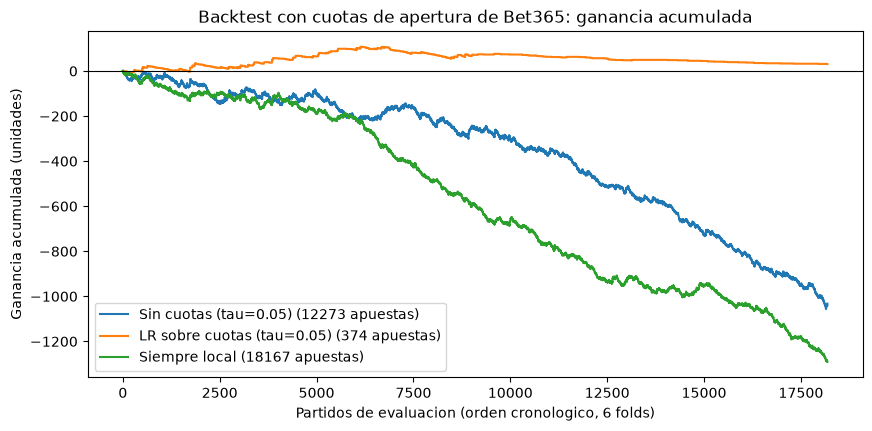

ganancia final (unidades) -> sin cuotas: -1032.4 | LR sobre cuotas: 30.5 | siempre local: -1290.3

ROI por fold (sin cuotas, tau = 0.05, B365):
      size    mean
fold              
1819  1987 -0.0595
1920  1899 -0.0456
2021  2173 -0.0266
2122  2197 -0.0898
2223  1965 -0.1279
2324  2052 -0.1566


In [12]:
# --- ganancia acumulada de las estrategias principales (test), B365
orden = np.argsort(pd.to_datetime(bt['Date'], dayfirst=True, format='mixed').to_numpy())
def acumulada(hay, gan):
    g = np.where(hay, gan, 0.0)[orden]
    return np.cumsum(g)

hay_n, _, gan_n, _ = apuestas(Pmod['NM'], O_B365, 0.05)
hay_l, _, gan_l, _ = apuestas(Pmod['lr'], O_B365, 0.05)
okb = ~np.isnan(O_B365).any(axis=1)
gan_h = np.where(yb == 0, np.nan_to_num(O_B365[:, 0]) - 1, -1.0)
fig, ax = plt.subplots(figsize=(10, 4.5))
for etiqueta, (hay, gan) in {'Sin cuotas (tau=0.05)': (hay_n, gan_n), 'LR sobre cuotas (tau=0.05)': (hay_l, gan_l), 'Siempre local': (okb, gan_h)}.items():
    ax.plot(acumulada(hay, gan), label=f'{etiqueta} ({int(hay.sum())} apuestas)')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Partidos de evaluacion (orden cronologico, 6 folds)'); ax.set_ylabel('Ganancia acumulada (unidades)')
ax.set_title('Backtest con cuotas de apertura de Bet365: ganancia acumulada'); ax.legend(); plt.show()
print('ganancia final (unidades) -> sin cuotas:', round(float(np.where(hay_n, gan_n, 0).sum()), 1), '| LR sobre cuotas:', round(float(np.where(hay_l, gan_l, 0).sum()), 1),
      '| siempre local:', round(float(np.where(okb, gan_h, 0).sum()), 1))
# ROI por fold (sin cuotas, tau = 0.05)
r_f = pd.DataFrame({'fold': fold_b[hay_n], 'g': gan_n[hay_n]}).groupby('fold').g.agg(['size', 'mean']).round(4)
print('\nROI por fold (sin cuotas, tau = 0.05, B365):'); print(r_f.to_string())

**Hallazgo.** Ganancia acumulada en los 6 folds con cuotas de apertura de Bet365 (`τ = 0.05`):

| Estrategia | Apuestas | Ganancia final (unidades) |
|---|---|---|
| Sin cuotas | ≈ 12,300 | **−1,032** |
| LR sobre cuotas | ≈ 370 | **+31** |
| Siempre local | ≈ 18,200 | −1,290 |

El ROI del modelo sin cuotas es **negativo en los 6 folds** (de −2.7% en 2020/21 a −15.7% en 2023/24), es decir, no es un efecto de una temporada.

**Decisión.** Un modelo que no usa las cuotas **no es rentable**; y el que las usa solo rinde cerca de 0, y solo en una casa.

### Paso 7b — ¿Es información o es "comprar barato"? Precio blando vs. precio afilado

**Qué vamos a hacer.** El único resultado con ROI positivo en el backtest es el de la LR sobre cuotas con **Bet365**; con Pinnacle no aparece. Eso sugiere que no se trata de información, sino de **diferencias de precio entre casas**: Bet365 (margen ≈ 6%) a veces paga más que la probabilidad justa que implica Pinnacle (margen ≈ 3.4%, considerada la referencia más eficiente).

Para separarlo se prueba una estrategia **sin ningún modelo**: apostar en Bet365 al resultado con mayor `EV = p_justa(Pinnacle) × cuota_B365 − 1`, si `EV > τ`. Se usan dos referencias para `p_justa`: la apertura y el cierre de Pinnacle (esta última es la mejor estimación de la probabilidad real).

**Por qué.** Si esta estrategia gana lo mismo que la LR, la ganancia viene de comprar barato entre casas, no de predecir; y es una ventaja que depende de poder apostar en la casa que paga más, no del modelo.

In [13]:
k = ['Season', 'Date', 'HomeTeam', 'AwayTeam']
b2 = bt[k + ['fold', 'y']].merge(ps[k + ['PSH', 'PSD', 'PSA', 'PSCH', 'PSCD', 'PSCA']], on=k, how='left')
OB = odds.loc[bt['idx'], ['B365H', 'B365D', 'B365A']].to_numpy(float)
y2 = b2['y'].to_numpy(); f2 = b2['fold'].to_numpy()
def justa(c):
    inv = 1 / b2[c].to_numpy(float)
    return inv / inv.sum(1, keepdims=True)
referencias = {'Pinnacle apertura': justa(['PSH', 'PSD', 'PSA']), 'Pinnacle cierre': justa(['PSCH', 'PSCD', 'PSCA'])}
filas = []
for nom, Pf in referencias.items():
    ok_ = ~np.isnan(Pf).any(axis=1) & ~np.isnan(OB).any(axis=1)
    ev = np.where(ok_[:, None], Pf * OB - 1, -np.inf)
    j = ev.argmax(1); emax = ev.max(1)
    gan = np.where(y2 == j, OB[np.arange(len(j)), j] - 1, -1.0)
    for tau in (0.0, 0.02, 0.05, 0.10):
        hay = emax > tau
        for etiqueta, mk_ in (('2018/19-2021/22', f2 <= 2122), ('2022/23-2023/24', f2 >= 2223), ('todos', np.ones(len(f2), bool))):
            g = gan[hay & mk_]
            if len(g) < 30:
                continue
            bs = np.array([g[rng.integers(0, len(g), len(g))].mean() for _ in range(500)])
            filas.append(dict(referencia=nom, tau=tau, periodo=etiqueta, apuestas=len(g), roi=g.mean(), ic=f'[{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]',
                              p_roi_pos=float((bs <= 0).mean()), ev_prometido=float(emax[hay & mk_].mean())))
sb = pd.DataFrame(filas)
sb.to_csv(DATA + 'backtest_precio_blando.csv', index=False)
print('Apostar en B365 cuando paga mas que la probabilidad justa de Pinnacle (sin modelo):')
print(sb.round(4).to_string(index=False))

Apostar en B365 cuando paga mas que la probabilidad justa de Pinnacle (sin modelo):
       referencia  tau         periodo  apuestas    roi               ic  p_roi_pos  ev_prometido
Pinnacle apertura 0.00 2018/19-2021/22      2259 0.0619 [-0.031, +0.158]      0.102        0.0338
Pinnacle apertura 0.00 2022/23-2023/24       724 0.0744 [-0.073, +0.256]      0.186        0.0296
Pinnacle apertura 0.00           todos      2983 0.0649 [-0.018, +0.151]      0.060        0.0328
Pinnacle apertura 0.02 2018/19-2021/22      1165 0.0935 [-0.037, +0.232]      0.116        0.0575
Pinnacle apertura 0.02 2022/23-2023/24       341 0.0179 [-0.232, +0.299]      0.486        0.0532
Pinnacle apertura 0.02           todos      1506 0.0764 [-0.049, +0.218]      0.124        0.0565
Pinnacle apertura 0.05 2018/19-2021/22       481 0.0991 [-0.157, +0.390]      0.224        0.0938
Pinnacle apertura 0.05 2022/23-2023/24       131 0.2992 [-0.199, +0.831]      0.114        0.0874
Pinnacle apertura 0.05           t

**Hallazgo.** Apostando en Bet365 sin ningún modelo, cuando su cuota supera la probabilidad justa de Pinnacle:

| Referencia de probabilidad justa | τ | Periodo | Apuestas | ROI | IC 95% |
|---|---|---|---|---|---|
| Pinnacle **apertura** | 0.00 | todos | 2,983 | +6.5% | [−1.8%, +15.1%] |
| Pinnacle apertura | 0.00 | 2022/23–2023/24 | 724 | +7.4% | [−7.3%, +25.6%] |
| Pinnacle apertura | 0.02 | todos | 1,506 | +7.6% | [−4.9%, +21.8%] |
| Pinnacle **cierre** | 0.00 | todos | 10,169 | **+8.2%** | [+4.6%, +11.8%] |
| Pinnacle cierre | 0.10 | todos | 1,936 | **+26.8%** | [+15.5%, +37.7%] |

**Interpretación.**

1. **La ventaja positiva no viene del modelo, viene del precio.** Bet365 paga a veces más que la probabilidad justa de Pinnacle; esa discrepancia de precios explica el único ROI positivo de LR con B365 y desaparece con Pinnacle.
2. **Con la referencia de apertura** (la única implementable, porque ambos precios se conocen a la vez) el ROI es ≈ +6.5% pero **no significativo** (IC incluye 0; con 2,983 apuestas).
3. **Con la referencia de cierre** el resultado es claramente positivo (+8.2%, IC [+4.6%, +11.8%]), pero **no es implementable**: usa información del cierre para decidir una apuesta que se coloca a la apertura. Es un límite superior, y confirma lo del Paso 6: entre apertura y cierre el mercado incorpora información que Bet365 todavía no había reflejado en su precio.
4. Las ventajas de este tipo son reales en la práctica solo mientras la casa no limite la cuenta del apostador, y las cuotas de football-data se capturan en un instante concreto, no necesariamente simultáneo entre casas.

**Decisión.** Reportar esto como una **observación sobre precios**, no como una estrategia validada: sin modelo no hay información; el único canal de ganancia observado es la diferencia entre casas, y la versión implementable no es estadísticamente distinguible de cero.

## Paso 8 — ¿Un modelo mal calibrado puede acertar más pero perder dinero?

**Qué vamos a hacer.** Cerrar la hipótesis (iii) del informe con las predicciones y el backtest de este cuaderno: para los cuatro modelos de probabilidad (sin cuotas, LR sobre cuotas, HGB sobre F1 y apilado) comparar la **accuracy**, el **ECE** y el **ROI** que obtienen apostando con cuotas de Bet365 (τ = 0), junto con el **valor esperado que el propio modelo prometía**.

**Por qué.** Si un modelo acierta más pero pierde dinero, la accuracy y la calibración promedio no sirven para juzgar una estrategia de apuestas; esta es la prueba directa.

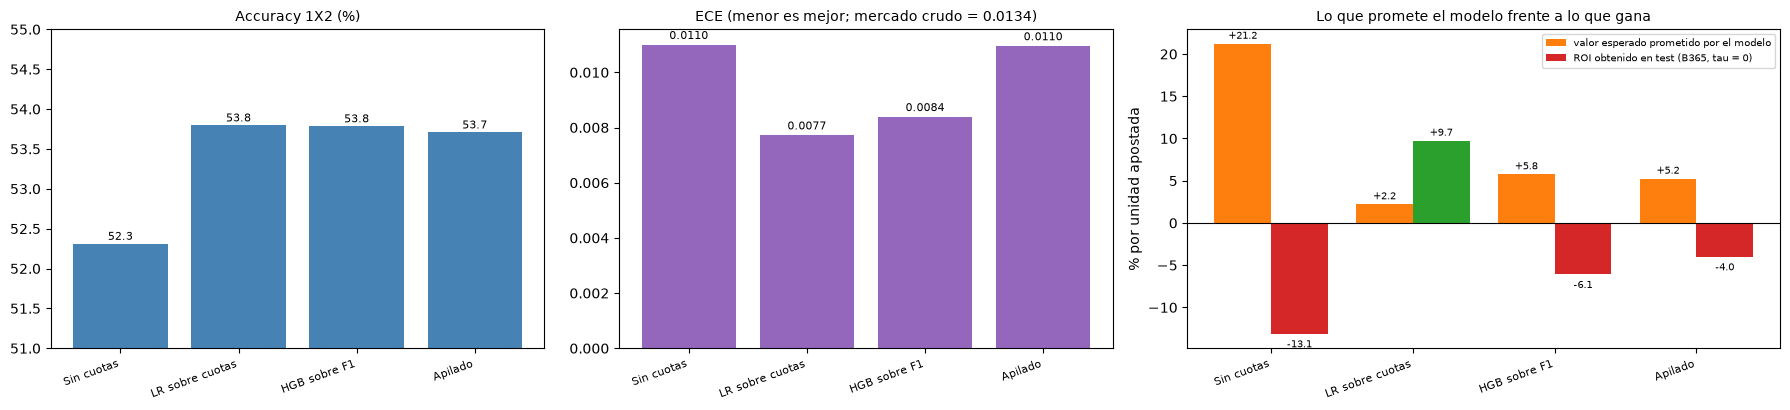

{'Sin cuotas': 5227, 'LR sobre cuotas': 939, 'HGB sobre F1': 2610, 'Apilado': 2955}


In [14]:
def ece10(p, o, nb=10):
    b_ = np.minimum((p * nb).astype(int), nb - 1)
    return float(sum((b_ == k).mean() * abs(o[b_ == k].mean() - p[b_ == k].mean()) for k in np.unique(b_)))
oo3 = pd.read_csv(DATA + 'predicciones_oof.csv'); bt_r = pd.read_csv(DATA + 'backtest_resultados.csv'); yy_ = oo3['y'].to_numpy()
filas = []
for k, nom in (('NM', 'Sin cuotas (goles -> prob.)'), ('lr', 'LR sobre cuotas'), ('hgb', 'HGB sobre F1'), ('stack', 'Apilado (mercado + y_NM)')):
    P_ = oo3[[f'P_{k}_H', f'P_{k}_D', f'P_{k}_A']].to_numpy()
    e = float(np.mean([ece10(P_[:, j], (yy_ == j)) for j in range(3)]))
    r_b = bt_r[(bt_r.casa == 'B365') & (bt_r.modelo == k) & (bt_r.tau == 0.0)].iloc[0]
    filas.append(dict(modelo=nom, acc_1x2=accuracy_score(yy_, P_.argmax(1)), log_loss=log_loss(yy_, P_), ECE=e, apuestas_test=int(r_b.n_test), ROI_B365_tau0=r_b.roi_test, EV_prometido=r_b.ev_prometido))
t8 = pd.DataFrame(filas).set_index('modelo')
fig, axs = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={'width_ratios': [1, 1, 1.2]})
xs = np.arange(len(t8)); nombres_ = [n_.split(' (')[0] for n_ in t8.index]
axs[0].bar(xs, t8.acc_1x2 * 100, color='steelblue'); axs[0].set_ylim(51, 55); axs[0].set_xticks(xs); axs[0].set_xticklabels(nombres_, rotation=20, ha='right', fontsize=8); axs[0].set_title('Accuracy 1X2 (%)', fontsize=10)
for x_, v in zip(xs, t8.acc_1x2 * 100): axs[0].text(x_, v + 0.05, f'{v:.1f}', ha='center', fontsize=8)
axs[1].bar(xs, t8.ECE, color='tab:purple'); axs[1].set_xticks(xs); axs[1].set_xticklabels(nombres_, rotation=20, ha='right', fontsize=8); axs[1].set_title('ECE (menor es mejor; mercado crudo = 0.0134)', fontsize=10)
for x_, v in zip(xs, t8.ECE): axs[1].text(x_, v + 0.0002, f'{v:.4f}', ha='center', fontsize=8)
axs[2].bar(xs - 0.2, t8.EV_prometido * 100, 0.4, color='tab:orange', label='valor esperado prometido por el modelo'); axs[2].bar(xs + 0.2, t8.ROI_B365_tau0 * 100, 0.4, color=['tab:green' if v > 0 else 'tab:red' for v in t8.ROI_B365_tau0], label='ROI obtenido en test (B365, tau = 0)')
axs[2].axhline(0, color='k', lw=0.8); axs[2].set_xticks(xs); axs[2].set_xticklabels(nombres_, rotation=20, ha='right', fontsize=8); axs[2].set_ylabel('% por unidad apostada'); axs[2].legend(fontsize=7); axs[2].set_title('Lo que promete el modelo frente a lo que gana', fontsize=10)
for x_, (a_, b_) in enumerate(zip(t8.EV_prometido * 100, t8.ROI_B365_tau0 * 100)): axs[2].text(x_ - 0.2, a_ + 0.6, f'{a_:+.1f}', ha='center', fontsize=7); axs[2].text(x_ + 0.2, b_ + (0.6 if b_ >= 0 else -1.6), f'{b_:+.1f}', ha='center', fontsize=7)
plt.tight_layout(); plt.show()
print({n_: int(a) for n_, a in zip(nombres_, t8.apuestas_test)})

**Qué encontramos.**

| Modelo | Accuracy 1X2 | Log loss | ECE | Apuestas (evaluación, τ = 0) | ROI en B365 | EV prometido |
|---|---|---|---|---|---|---|
| Sin cuotas (goles → prob.) | 52.3% | 0.9893 | 0.0110 | 5,227 | **−13.1%** | +21.2% |
| HGB sobre F1 | 53.8% | 0.9680 | 0.0084 | 2,610 | −6.1% | +5.8% |
| Apilado | 53.7% | 0.9684 | 0.0110 | 2,955 | −4.0% | +5.2% |
| LR sobre cuotas | 53.8% | 0.9657 | 0.0077 | 939 | +9.7% (IC [−0.7%, +20.3%]) | +2.2% |

- El modelo que pierde dinero (sin cuotas) **no es el peor calibrado**: su ECE (0.0110) es **mejor que el del mercado crudo** (0.0126) y comparable al de los demás. Tampoco "acierta más": acierta 1.5 pp **menos**.
- Lo que explica el −13.1% **no es la calibración promedio sino su calibración condicional en los partidos donde discrepa del mercado**: promete +21.2% de valor y obtiene −13.1% (la "maldición del ganador": las apuestas que elige son justo aquellas donde su error es mayor).
- Una diferencia de 1.5 pp de accuracy se traduce en una diferencia de **22.8 pp de ROI** (de −13.1% a +9.7%).

**Qué significa para nuestro caso.** La accuracy es una métrica casi inútil para valorar una estrategia de apuestas, y la buena calibración global no garantiza rentabilidad: lo que importa es no tener errores sistemáticos justo donde se apuesta. Por eso en todo el proyecto se juzga con log loss, calibración e intervalos, y no con el porcentaje de aciertos.

**Decisión.** La hipótesis (iii) **no se cumple en la forma planteada**; queda documentada la maldición del ganador como explicación del mal resultado del modelo sin cuotas.

## Resumen y siguiente paso

| Pregunta | Respuesta |
|---|---|
| **A.** ¿Quién gana mejor: cuotas o sin cuotas? | **Cuotas:** 71.6% vs 69.7% de acierto del ganador (RMSE de GD 1.625 vs 1.670) |
| ¿Qué pasa cuando discrepan? | Acierta el modelo con cuotas el 57.5% de las veces (*p* < 0.0001) |
| ¿Combinarlos ayuda? | No: promedio (0.9740) y apilado (0.9684) no mejoran al mercado (0.9664) |
| ¿Queda información sin explicar? | No: `R²` del residuo = −0.001 |
| **B.** ¿El mercado está mal calibrado? | Ligeramente: favoritos +2 a +4 pp, longshots −1 a −2 pp; **con la normalización por potencia el sesgo casi desaparece** |
| ¿Hay ligas o temporadas ineficientes? | Solo 2016/17 sobrevive a la corrección; COVID y ligas **no** |
| **C.** ¿Cuánta información entra entre apertura y cierre? | Mucha: log loss 0.9658 → 0.9620; el cierre subsume a la apertura |
| ¿La anticipa el modelo sin cuotas? | No: r = −0.011; CLV −0.11 a −0.17 pp, igual o peor que el lado contrario (−0.06 pp) |
| **D.** ¿Es rentable apostar con el modelo sin cuotas? | **No:** ROI −11.8% a −16.5% (promete +21% a +38%) |
| ¿Y con el modelo sobre cuotas? | Entre −6.4% (Pinnacle) y +9.7% (B365, IC [−0.7%, +20.3%]): no significativo |
| ¿Se reproduce la regla del paper (\|ŷ\| > 2)? | 642 apuestas, ROI −1.3% [−4.5%, +2.0%]: no se distingue de 0 |
| ¿Hay algún canal de ganancia? | Solo **precio**: Bet365 vs. probabilidad justa de Pinnacle (+6.5% con apertura, no significativo; +8.2% con cierre, no implementable) |

**Para el informe.** Cuatro análisis independientes (modelo de residuo, movimiento de línea, CLV y backtest) coinciden: *el mercado es eficiente respecto a la información de fundamentos disponible*. El modelo sin cuotas pierde dinero y es sobreconfiado; las pequeñas desviaciones del mercado (sesgo favorito–longshot, diferencias entre casas) son del orden del margen y no son explotables de forma estadísticamente demostrable. El backtest sobre el **test holdout** (2024/25–2025/26) está en `08_modelo_final.ipynb`, Paso 8.

**Siguiente (en el orden acordado).** SVM / XGBoost / MLP sobre los bloques ya evaluados, con hiperparámetros elegidos igual que en el Paso 1 (ventana de ajuste, rejilla corta, desempate por simplicidad), y su comparación con los modelos actuales.